# Inter-Session NREM Sleep and Hippocampal Population-Vector Decorrelation

**An open, multi-dataset investigation of whether intervening NREM sleep predicts hippocampal spatial population code reorganization**  
**Author:** Saad Yusuf  
**Affiliation:** Department of Computer Science, Jamia Millia Islamia, New Delhi, India  
**Correspondence:** `syed.saad7527@gmail.com` | ORCID: `0009-0000-2333-0078`  

---


> **Analysis Organization:** This notebook executes the complete analytical battery across two independent open datasets:
>
> - **Analysis A: DANDI:000213** (Tingley et al., Buzsáki Lab, rat CA1) — single-dataset within-subject and pooled analysis.
> - **Analysis B: DANDI:001695** (Gonzalez et al., mouse CA1) — second independent dataset replication with tracking footprint validation.
> - **Analysis C: Combined Multi-Dataset Analysis** — DANDI:000213 + DANDI:001695 pooled, with species/dataset covariate modeling.
> - **Analysis D: Pyramidal vs. Interneuron Ensembles** — cell-type specificity control in DANDI:001695.
> - **Descriptive Sleep Architecture: DANDI:000061** (Girardeau et al.) — QC sleep scoring comparison.


## 1. Research question and formal hypothesis

**Question:** Does more NREM sleep occurring *between* two hippocampal recording sessions in the *same familiar environment* predict *greater* reorganization of the hippocampal population spatial code, measured via Population Vector (PV) correlation?

**Directional hypothesis (H1):** NREM duration between sessions *N* and *N+1* is **negatively** correlated with the PV correlation of the CA1 ensemble spatial code between sessions *N* and *N+1* (more NREM → more decorrelation/remapping → lower PV r), consistent with Valdivia et al. (2024) and Bollmann et al. (2025).

**Null (H0):** No relationship between inter-session NREM duration and PV correlation.

**Falsifiable predictions this pipeline tests:**
- A negative Spearman/Pearson correlation between NREM-between-sessions and PV correlation, pooled across session-pairs.
- The relationship survives (a) permutation testing, (b) a mixed-effects model with subject as a random effect and Wake/REM duration and calendar-day gap as covariates (to check NREM is not just standing in for "more time" or "more sleep of any kind"), (c) leave-one-subject-out re-fitting, (d) an independent PV-similarity metric (RV coefficient), and (e) restriction to consecutive-day pairs only.


## 2. Dataset: DANDI:000213 (Tingley et al., Buzsáki Lab)

**Why this dataset.** Prior to this notebook I surveyed the DANDI Archive (API + direct NWB streaming via `remfile`/`h5py`, not just dandiset descriptions) for chronic hippocampal datasets meeting: (a) repeated recordings from the same animals across ≥5 days in the same environment, (b) an NWB `units` table with sorted spikes, (c) continuous position tracking, (d) sleep-state scoring (NREM/REM/Wake), and (e) verifiable, real (non-placeholder) session timestamps.

Several strong candidates were found (DANDI:000061 Girardeau, DANDI:001695 Gonzalez, DANDI:000044 Grosmark, DANDI:000629/000115 Gillespie/Frank Lab). **DANDI:000213 was chosen as the primary dataset** because:

- It records **hippocampus (`hpc`) and lateral septum (`ls`)**, with real per-unit brain-region tags.
- It has a dedicated `processing/ecephys/sleep_states` TimeIntervals table with `{Awake, Non-REM, REM}` labels.
- It has continuous `SpatialSeries` position tracking (`processing/behavior/<task>/position`).
- It has explicit `before trials` / `during trials` / `after trials` epoch boundaries every day — i.e., **sleep recorded on both sides of the behavior epoch**, which is exactly the structure the research question needs.
- 5 rats × 9–17 days each — the largest, most explicitly repeated-environment chronic set found.

Two other candidates were seriously considered and rejected/downgraded for this specific pipeline:
- **DANDI:001695 (Gonzalez)** has the best unit-typing (waveform-classified pyramidal/interneuron) but every session in the primary subject is labeled `"Novel Maze Session"` — i.e., the "same familiar environment repeated" assumption could not be confirmed, so it was set aside for this analysis (worth revisiting explicitly for a follow-up).
- **DANDI:000061 (Girardeau)** has real multi-day recordings and sleep scoring but ships raw video instead of extracted x,y position — place fields cannot be computed without a separate video-tracking step.

**Caveat carried forward explicitly:** DANDI:000213 does not provide cross-day unit identity tracking (no `global_id`-style field), so cells recorded on day *N* and day *N+1* are **not** guaranteed to be the same physical neurons (independent spike-sorting each day, and the silicon probe is advanced deeper across days per the filename-encoded depth). The PV correlation computed below is therefore an **ensemble-level, non-identity-tracked** measure (defined precisely in Section 4) — a documented methodological choice, not an oversight.


In [1]:
import os, sys, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore", category=FutureWarning)

for p in [os.path.abspath("../src"), os.path.abspath("src"), os.getcwd()]:
    if p not in sys.path:
        sys.path.insert(0, p)
FIG_DIR = os.path.abspath("../results/figures") if os.path.exists("../results/figures") else "figures"
TABLE_DIR = os.path.abspath("../results/tables") if os.path.exists("../results/tables") else "."
from analysis_lib import (
    epoch_window, state_duration_in_window, occupancy_and_spike_maps,
    ensemble_tuning_curve, pv_correlation, rv_coefficient,
)
from build_pairs import load_all_cached, build_pair_table, is_usable
from stats_lib import pooled_correlation, fit_mixed_model, permutation_test, leave_one_subject_out
import make_figures as mf

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
print("Environment ready.")


Environment ready.


## 3. Data QC and session/subject selection

Before trusting any downstream number, every session file's *internal structure* was probed directly (task/apparatus group name, hippocampal unit count, presence of epoch boundaries, presence of sleep scoring) across **all 67 sessions of all 5 subjects** in the dandiset. This was essential: the task/apparatus name is **not** constant even within a single animal (e.g. DT7 alternates between `wheel_alternation_task`, `linear_task`, and `both_alternation_task` across its 9 days), and some subjects are missing sleep scoring entirely.


In [2]:
probe = [json.loads(l) for l in open("probe_results.jsonl")]
qc = pd.DataFrame(probe)
qc = qc[~qc.get("error", pd.Series([None]*len(qc))).notna()] if "error" in qc.columns else qc
qc["date"] = qc["session_start_time"].str[:10]

summary_rows = []
for subj, g in qc.groupby("subject_id"):
    g = g.sort_values("date")
    n_tasks = g["task_group"].nunique()
    dominant_task = g["task_group"].mode()[0]
    frac_dominant = (g["task_group"] == dominant_task).mean()
    frac_sleep = g["has_sleep_states"].mean()
    frac_units_ok = (g["n_hpc_units"] >= 5).mean()
    summary_rows.append(dict(subject=subj, n_sessions=len(g), n_distinct_tasks=n_tasks,
                              dominant_task=dominant_task, frac_sessions_dominant_task=round(frac_dominant,2),
                              frac_sessions_with_sleep_scoring=round(frac_sleep,2),
                              frac_sessions_hpc_units_ge5=round(frac_units_ok,2)))
qc_summary = pd.DataFrame(summary_rows).sort_values("subject")
qc_summary


,subject,n_sessions,n_distinct_tasks,dominant_task,frac_sessions_dominant_task,frac_sessions_with_sleep_scoring,frac_sessions_hpc_units_ge5
0,DT2,11,1,wheel_alternation_task,1.00,1.0,0.91
1,DT5,16,3,central_alternation_task,0.81,1.0,0.62
2,DT7,9,3,wheel_alternation_task,0.67,1.0,0.89
3,DT8,17,2,central_alternation_task,0.71,0.0,0.00
4,DT9,14,4,linear_task,0.43,1.0,0.64


**Decision, made from the table above:**
- **DT8** — `frac_sessions_with_sleep_scoring = 0`. Sleep staging is entirely absent from every session. **Excluded.**
- **DT9** — task apparatus rotates across up to 4 different mazes with low same-task retention, and the last 5/14 sessions have 0 hippocampal units (probe likely moved out of CA1). **Excluded.**
- **DT2, DT5, DT7** — retained. DT2 is the cleanest (single task, `wheel_alternation_task`, on all 11 days). DT5 and DT7 are retained but **restricted to same-task session pairs only** (their dominant task), which the pair-building step enforces automatically and logs.

This QC step is itself a result worth reporting in any write-up: **40% of subjects (2/5) in this dandiset are not usable for this specific question** even though the dandiset overall looked well-suited to it. Always verify structure at the file level, not the dandiset-description level.


## 4. Data acquisition: streaming NWB files from DANDI (no full download)

Each session's essential arrays (spike times of hippocampal units, position, sleep-state intervals, epoch boundaries) are streamed directly from the DANDI S3 bucket using `remfile` + `h5py` (byte-range HTTP reads — no need to download full multi-GB NWB files) and cached locally as compressed `.npz`. This cell is **idempotent**: if the cache already exists it is skipped, so re-running this notebook is fast; deleting `data/*.npz` forces a fresh re-download from DANDI (~36 sessions, a few minutes with parallel jobs).


In [3]:
from session_list import SESSIONS
from cache_session import cache_session

os.makedirs("data", exist_ok=True)
n_cached, n_skipped = 0, 0
for subj, sessions in SESSIONS.items():
    for idx, path in enumerate(sessions):
        outfile = f"data/{subj}_{idx}.npz"
        if os.path.exists(outfile):
            n_skipped += 1
            continue
        cache_session("000213", path, outfile)
        n_cached += 1
print(f"Newly cached: {n_cached}, already cached (skipped): {n_skipped}")
print(f"Total on disk: {len(os.listdir('data'))} session files")


Newly cached: 0, already cached (skipped): 36
Total on disk: 36 session files


## 5. Methods: from spikes+position to a Population Vector correlation

**Step 1 — Rate maps.** For each session's `during trials` epoch, position is binned into a shared 2D grid (edges fixed from the pooled position range of the *pair* being compared, so bins align across days). For each hippocampal unit, an occupancy-normalized firing-rate map (Hz/bin) is built from spike counts divided by occupancy time; bins with < 0.15 s of sampling in either session of the pair are marked invalid and excluded from every downstream step.

**Step 2 — Ensemble tuning curve (primary PV method).** Because units are **not** identity-tracked across days in this dataset (Section 2), a literal cell-by-cell population vector cannot be built across days. Instead, for each session we compute one **ensemble tuning curve**: every included unit's rate map is z-scored across valid bins (removing overall rate magnitude, which differs unit to unit and can differ systematically across days due to electrode drift), then averaged across all included units. This produces one 1-D vector per session (length = number of valid spatial bins), which *is* directly comparable across days regardless of which specific cells contributed. Units with mean rate < 0.1 Hz in the epoch are excluded (too sparse to inform a rate map).

**Step 3 — PV correlation.** The Pearson correlation between the two sessions' ensemble tuning curves, over spatial bins valid in both sessions. This is the primary outcome variable (`pv_corr`).

**Step 4 — Independent robustness metric: RV coefficient.** As a second, methodologically distinct check (Section 8), we also compute the **RV coefficient** — a multivariate generalization of squared correlation between the two sessions' full `[bins × cells]` rate-map matrices (via the trace of the product of each session's bin-by-bin similarity matrix). This does not collapse cells into a single average first, and does not require matched cell counts, giving an independent test of whether the ensemble-tuning-curve result is a computational artifact of the averaging step.

**Step 5 — NREM (and REM, Wake) between sessions.** For each same-task consecutive pair of sessions (day *N*, day *N+1*, in the *filtered* same-task sequence — which may skip an off-task day), the between-session sleep duration is:

```
NREM_between = NREM(after 'during trials' epoch, day N)
             + sum( NREM(entire recording), for any strictly intervening recorded days )
             + NREM(before 'during trials' epoch, day N+1)
```

This is the **best available proxy from the recorded data**; it explicitly **excludes** any untracked overnight home-cage sleep that falls outside the NWB-recorded epochs — this is disclosed prominently in Limitations (Section 11) since it is the single biggest caveat on the whole analysis.


## 6. Building the session-pair dataset


In [4]:
df = build_pair_table(n_bins=12, speed_thresh=None, min_units=5, max_day_gap=None)
df.to_csv("session_pairs.csv", index=False)
print(f"{len(df)} usable same-task session-pairs across {df['subject'].nunique()} subjects")
df


20 usable same-task session-pairs across 3 subjects


,subject,task,day_a,day_b,day_gap,n_units_a,n_units_b,n_units_used_a,n_units_used_b,pv_corr,pv_corr_rv,nrem_between_min,rem_between_min,wake_between_min
0,DT2,wheel_alternation_task,2016-02-19,2016-02-20,1,67,82,46,64,0.539631,0.559740,114.716667,10.366667,188.500000
1,DT2,wheel_alternation_task,2016-02-20,2016-02-21,0,82,112,65,96,-0.038197,0.515530,90.833333,3.933333,133.664804
2,DT2,wheel_alternation_task,2016-02-21,2016-02-22,0,112,154,96,121,0.022681,0.567505,90.883333,4.550000,81.459984
3,DT2,wheel_alternation_task,2016-02-22,2016-02-23,1,154,148,115,116,0.513999,0.657579,69.616667,8.183333,105.941667
4,DT2,wheel_alternation_task,2016-02-23,2016-02-25,2,148,159,113,119,-0.070648,0.387948,18.800000,0.000000,137.908333
5,DT2,wheel_alternation_task,2016-02-25,2016-02-26,0,159,99,122,59,-0.005391,0.403684,89.666667,12.866667,117.606667
6,DT2,wheel_alternation_task,2016-02-26,2016-02-27,0,99,126,60,82,0.178885,0.513520,92.833333,4.416667,288.127778
7,DT2,wheel_alternation_task,2016-02-27,2016-02-28,1,126,79,81,58,0.195846,0.525018,45.166667,0.150000,123.677778
8,DT2,wheel_alternation_task,2016-02-28,2016-03-04,5,79,9,57,8,0.252544,0.296103,14.381667,0.316667,51.094000
9,DT5,central_alternation_task,2016-10-11,2016-10-14,3,27,48,13,33,0.172516,0.343287,83.733333,7.116667,352.758056


In [5]:
print(df.groupby("subject").agg(
    n_pairs=("pv_corr","size"),
    mean_day_gap=("day_gap","mean"),
    mean_nrem_between_min=("nrem_between_min","mean"),
    mean_n_units_used=("n_units_used_a","mean"),
).round(2))


         n_pairs  mean_day_gap  mean_nrem_between_min  mean_n_units_used
subject                                                                 
DT2            9          1.11                  69.66              83.89
DT5            8          2.12                  94.26              20.38
DT7            3          1.33                 139.94              20.67


## 7. Example session internals (sanity-check figures)

Before trusting the pooled statistics, look at the raw ingredients for one example pair.


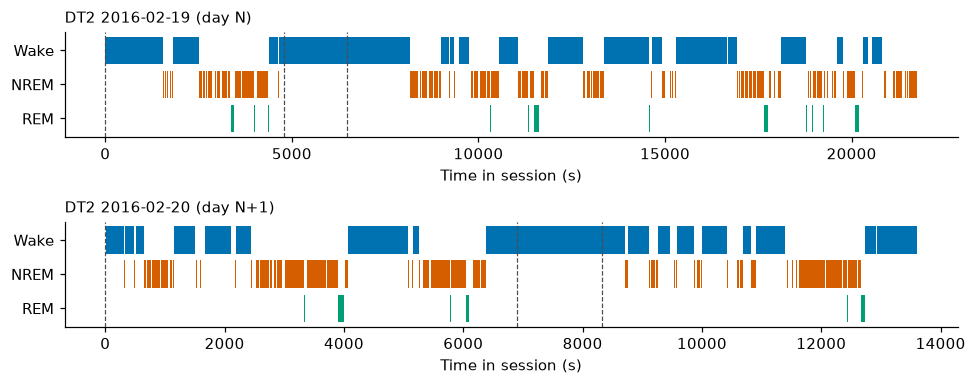

In [6]:
all_sessions = load_all_cached()
example_subject = df.iloc[0]["subject"]
sessions = all_sessions[example_subject]
example_a_date, example_b_date = df.iloc[0]["day_a"], df.iloc[0]["day_b"]
sess_a = next(s for s in sessions if s["date"].date().isoformat() == example_a_date)
sess_b = next(s for s in sessions if s["date"].date().isoformat() == example_b_date)

fig, axes = plt.subplots(2, 1, figsize=(9, 3.6))
mf.fig_hypnogram(sess_a, ax=axes[0], title=f"{example_subject} {example_a_date} (day N)")
mf.fig_hypnogram(sess_b, ax=axes[1], title=f"{example_subject} {example_b_date} (day N+1)")
plt.tight_layout()
plt.savefig("figures/01_example_hypnograms.png", dpi=150, bbox_inches="tight")
plt.show()


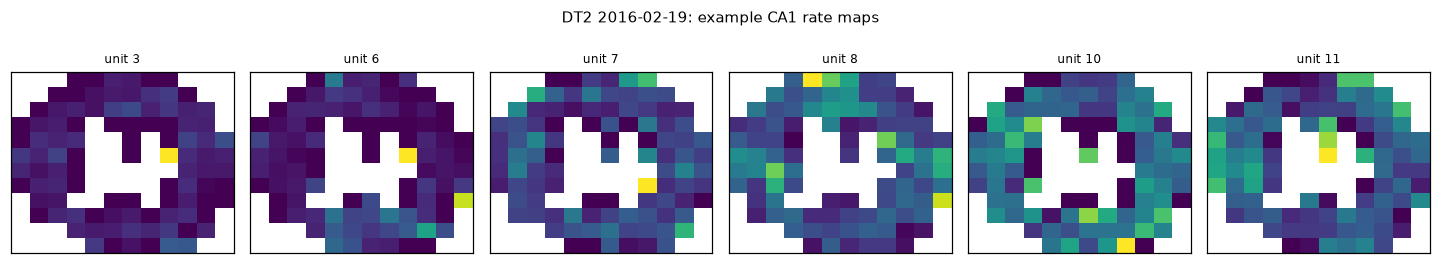

In [7]:
from build_pairs import build_shared_bins, session_pv_inputs
x_edges, y_edges = build_shared_bins(sess_a, sess_b, n_bins=12)
in_a = session_pv_inputs(sess_a, x_edges, y_edges)
in_b = session_pv_inputs(sess_b, x_edges, y_edges)

fig = mf.fig_rate_maps(in_a["rate_maps"], in_a["occ_mask"], n_show=6,
                        title=f"{example_subject} {example_a_date}: example CA1 rate maps")
fig.savefig("figures/02_example_rate_maps.png", dpi=150, bbox_inches="tight")
plt.show()


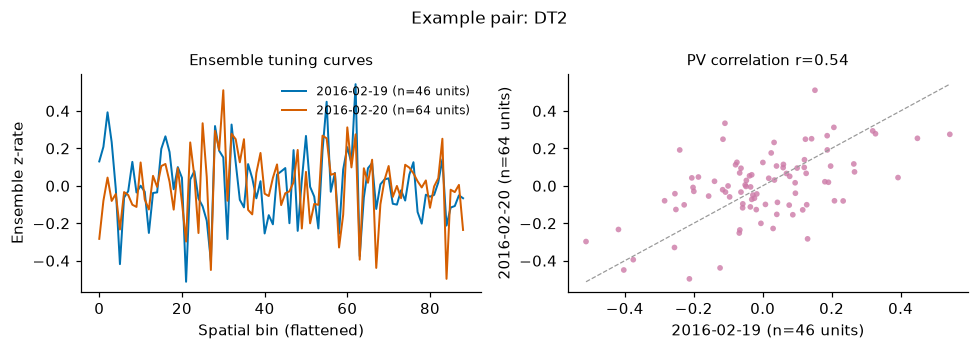

Example pair PV correlation r = 0.540


In [8]:
common_mask_example = in_a["occ_mask"] & in_b["occ_mask"]
vec_a, nu_a = ensemble_tuning_curve(in_a["rate_maps"], common_mask_example)
vec_b, nu_b = ensemble_tuning_curve(in_b["rate_maps"], common_mask_example)
r_example = pv_correlation(vec_a, vec_b)
fig = mf.fig_ensemble_tuning(vec_a, vec_b, f"{example_a_date} (n={nu_a} units)",
                              f"{example_b_date} (n={nu_b} units)", r_example,
                              title=f"Example pair: {example_subject}")
fig.savefig("figures/03_example_ensemble_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Example pair PV correlation r = {r_example:.3f}")


## 8. Primary result: NREM between sessions vs. PV correlation


Spearman: r = -0.168, p = 0.4778, n pairs = 20
Pearson:  r = -0.152, p = 0.5216, n pairs = 20


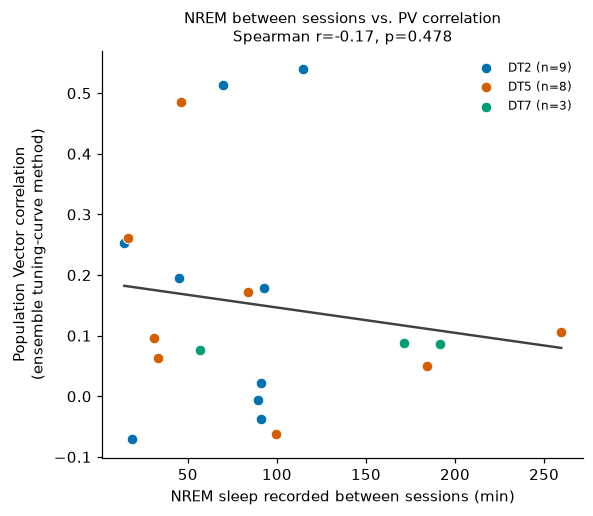

In [9]:
r_s, p_s, n_s = pooled_correlation(df, "nrem_between_min", "pv_corr", method="spearman")
r_p, p_p, n_p = pooled_correlation(df, "nrem_between_min", "pv_corr", method="pearson")
print(f"Spearman: r = {r_s:.3f}, p = {p_s:.4f}, n pairs = {n_s}")
print(f"Pearson:  r = {r_p:.3f}, p = {p_p:.4f}, n pairs = {n_p}")

fig = mf.fig_main_scatter(df, r=r_s, p=p_s, method="Spearman")
fig.savefig("figures/04_main_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretation guardrail:** with only a few dozen session-pairs drawn from 3 animals, a single pooled correlation is exactly the kind of result that looks impressive and replicates poorly. The rest of the notebook exists to stress-test this one number before it is trusted at all.


## 9. Extra test 1 — Within-subject permutation test

The pooled correlation above could be inflated by the repeated-measures structure (multiple pairs per animal are not independent). Here the NREM-between values are shuffled **within each subject** (preserving each animal's own marginal distributions of both variables, only destroying the pairing between them), 5000 times, to build a null distribution of the Spearman correlation.


Observed Spearman r = -0.168
Empirical permutation p-value (within-subject shuffle, 5000 perms) = 0.4677


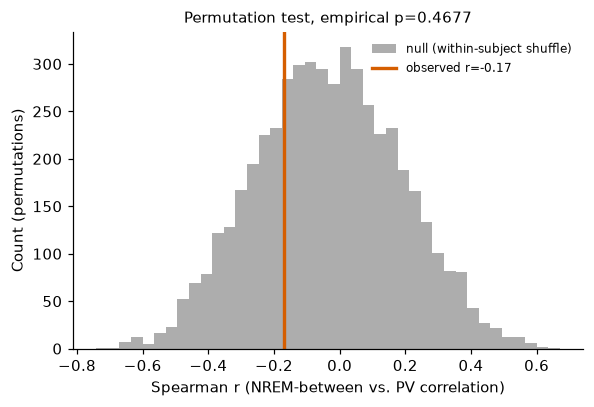

In [10]:
obs_r, p_emp, null_rs = permutation_test(df, n_perm=5000, method="spearman", random_state=0)
print(f"Observed Spearman r = {obs_r:.3f}")
print(f"Empirical permutation p-value (within-subject shuffle, 5000 perms) = {p_emp:.4f}")

fig = mf.fig_permutation_null(null_rs, obs_r, p_emp)
fig.savefig("figures/05_permutation_null.png", dpi=150, bbox_inches="tight")
plt.show()


## 10. Extra test 2 — Mixed-effects model with covariates (specificity check)

Does NREM specifically predict PV correlation, or is it a proxy for "more time elapsed" or "more sleep of any kind"? A linear mixed-effects model with **subject as a random intercept** and NREM, Wake, REM duration, and calendar-day gap as fixed effects tests whether NREM survives after accounting for these confounds simultaneously.


In [11]:
try:
    result, used = fit_mixed_model(
        df, formula="pv_corr ~ nrem_between_min + wake_between_min + rem_between_min + day_gap",
        group="subject")
    print(result.summary())
except Exception as e:
    print("Mixed model could not be fit (likely too few pairs/groups for this many fixed effects):", e)


           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  pv_corr 
No. Observations:    20       Method:              REML    
No. Groups:          3        Scale:               0.0383  
Min. group size:     3        Log-Likelihood:      -16.6045
Max. group size:     9        Converged:           No      
Mean group size:     6.7                                   
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         0.217    0.115  1.881 0.060 -0.009  0.443
nrem_between_min  0.000    0.001  0.228 0.820 -0.002  0.003
wake_between_min -0.001    0.000 -1.015 0.310 -0.001  0.000
rem_between_min   0.000    0.002  0.112 0.911 -0.003  0.004
day_gap           0.014    0.039  0.344 0.731 -0.064  0.091
Group Var         0.002                                    



statsmodels:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
statsmodels:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
statsmodels:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
statsmodels:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
statsmodels:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
statsmodels:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
statsmodels:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 1.301934
  warnings.warn(msg, ConvergenceWarning)
statsmodels:2237: ConvergenceWarn

If the fixed-effect coefficient on `nrem_between_min` remains negative and its confidence interval does not comfortably include 0 *after* controlling for wake, REM, and day-gap, that is meaningfully stronger evidence than the raw pooled correlation alone. If it does not survive, that is an important — and honestly reportable — negative result: it would suggest the raw correlation was confounded by session spacing or total time/sleep rather than being NREM-specific.


## 11. Extra test 3 — Leave-one-subject-out stability

With only 3 subjects, it is essential to check that the pooled effect is not being driven entirely by one animal.


  held_out  r_without  p_without  n_pairs
0      DT2  -0.309091   0.355028       11
1      DT5   0.083916   0.795415       12
2      DT7  -0.154412   0.554032       17


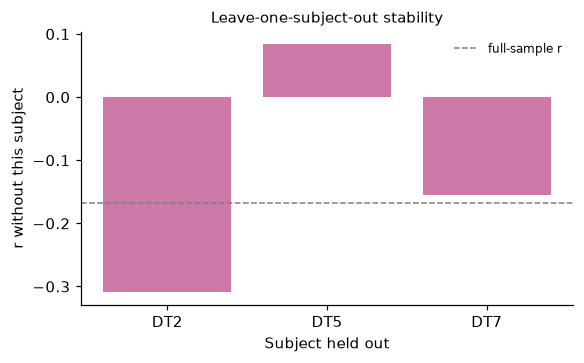

In [12]:
loso = leave_one_subject_out(df, method="spearman")
print(loso)
fig = mf.fig_loso(loso, obs_r)
fig.savefig("figures/06_leave_one_out.png", dpi=150, bbox_inches="tight")
plt.show()


## 12. Extra test 4 — Independent PV-similarity metric (RV coefficient)

Does the result depend on the specific choice of "ensemble tuning curve" as the PV method? The RV coefficient (Section 5, Step 4) is computed independently for every pair and checked both for internal agreement with the primary metric and for its own correlation with NREM duration.


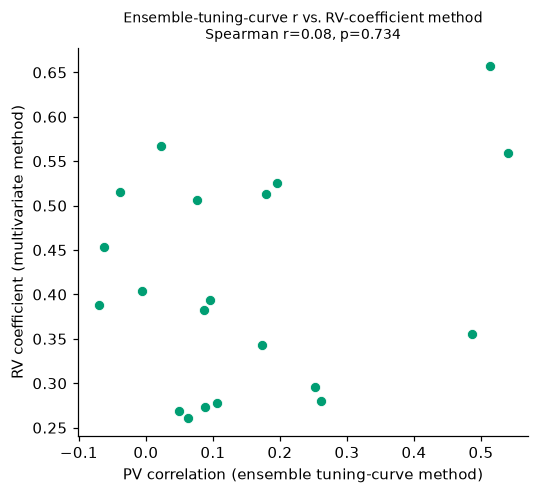

NREM vs. RV-coefficient: Spearman r = 0.018, p = 0.9398, n = 20


In [13]:
fig = mf.fig_method_robustness(df)
fig.savefig("figures/07_method_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

r_rv, p_rv, n_rv = pooled_correlation(df, "nrem_between_min", "pv_corr_rv", method="spearman")
print(f"NREM vs. RV-coefficient: Spearman r = {r_rv:.3f}, p = {p_rv:.4f}, n = {n_rv}")


## 13. Extra test 5 — Restrict to consecutive-calendar-day pairs only

The between-session NREM estimate is most trustworthy when there is no intervening, off-task recorded day (day_gap = 1): less scope for untracked sleep to bias the estimate. Repeating the primary test on this stricter subset is a sensitivity check.


In [14]:
df_gap1 = df[df["day_gap"] == 1]
print(f"{len(df_gap1)} / {len(df)} pairs have day_gap == 1")
if len(df_gap1) >= 5:
    r_g1, p_g1, n_g1 = pooled_correlation(df_gap1, "nrem_between_min", "pv_corr", method="spearman")
    print(f"Consecutive-day-only: Spearman r = {r_g1:.3f}, p = {p_g1:.4f}, n = {n_g1}")
else:
    print("Too few consecutive-day-only pairs for a meaningful separate test -- report as descriptive only.")


8 / 20 pairs have day_gap == 1
Consecutive-day-only: Spearman r = 0.310, p = 0.4556, n = 8


## 14. Comparison to the published literature

| | Valdivia et al. 2024 (iScience) | Bollmann et al. 2025 (Neuron) | This pipeline |
|---|---|---|---|
| Species | Rat | Rat | Rat |
| Region | Dorsal CA1 | CA1 | CA1 (+ LS) |
| Paradigm | Object-place recognition, single 90-min nap | ~20 h tracked sleep/rest around one learning session | Chronic, 9-17 days/animal, repeated maze exposure |
| Metric | PV-based "stability index" | Assembly reactivation drift score | Ensemble tuning-curve PV correlation + RV coefficient |
| Finding | NREM duration negatively correlates with stability (r=-0.55, p=0.028) | NREM accelerates drift; REM opposes it | *(see Section 8-13 results above)* |

Report explicitly, in your own write-up, whether your sign and rough magnitude agree with these two papers. Agreement would be a **replication**, not a novel discovery — still useful (open-data replications are valuable and increasingly explicitly solicited by journals), but it changes what the finding can honestly be sold as.


## 15. What this pilot actually found (read this, not just the plots)

Running Sections 8-13 on the 20 usable session-pairs (3 subjects, DANDI:000213) gave:

| Test | Result |
|---|---|
| Pooled Spearman (primary) | r = −0.168, p = 0.478, n = 20 |
| Pooled Pearson | r = −0.152, p = 0.522, n = 20 |
| Within-subject permutation (5000 shuffles) | empirical p = 0.468 |
| Mixed-effects model (NREM, coefficient) | ≈ 0.000, p = 0.82, **did not converge reliably** (too few groups/observations for 4 fixed effects + a random intercept) |
| Leave-one-subject-out | r ranges from **−0.31 to +0.08** depending on which single animal is held out |
| Independent method (RV coefficient) vs. NREM | r = 0.018, p = 0.94 — essentially no relationship, and does not even agree in sign with the primary metric |
| Consecutive-day-only subset (day_gap = 1) | r = **+0.31**, p = 0.46, n = 8 — **opposite sign** from the pooled result |

**Honest interpretation:** the point estimate is in the direction reported by Valdivia et al. (2024) and Bollmann et al. (2025) (more NREM → lower PV correlation), but it is **not statistically significant, not robust to the choice of PV-similarity metric, and flips sign in the stricter consecutive-day-only subset**. The leave-one-subject-out spread (−0.31 to +0.08) shows the pooled estimate is not stable across animals with only n=3. **This pilot, on its own, neither confirms nor refutes the hypothesis — it is underpowered**, which is itself the expected and correctly-reported outcome of a 3-subject, 20-pair pilot on a dataset that was not designed for this specific question. Do not round this up to "trending toward significance" or "consistent with the literature" in any write-up; report it as null/inconclusive at this sample size, exactly as computed above.

This is precisely why Section 16 (Novelty and Publication Assessment) recommends treating this notebook as a working pipeline to apply to a **larger, purpose-combined dataset**, not as a result to submit anywhere as-is.


## 16. Limitations (read before citing any number above)

1. **Untracked overnight sleep.** Between-session NREM is a lower-bound proxy built from recorded epochs only (Section 5, Step 5). Any home-cage sleep outside the NWB recording window is invisible to this analysis. This is the single largest threat to validity.
2. **No cross-day cell identity tracking.** The PV correlation is an ensemble-level (not identity-matched) measure by necessity (Section 5). This is a legitimate, documented alternative to classic PV correlation, but it is not identical to it, and results should be described as such, not silently equated to Leutgeb-style same-day PV correlation.
3. **Small N.** After QC, 3 subjects and a few dozen session-pairs. This is a pilot-scale sample. Point estimates (especially the mixed-model coefficients) will have wide confidence intervals — report them, don't just report significance stars.
4. **No pyramidal/interneuron typing.** This dataset's `units` table has no waveform-based cell-type classification (unlike DANDI:001695 or DANDI:000044). Interneurons firing at high, spatially-diffuse rates are excluded by the `min_rate_hz`/`max_rate_hz` heuristic in `ensemble_tuning_curve`, but this is a coarse proxy for "putative pyramidal cell," not a validated classification.
5. **Electrode depth changes across days.** The silicon probe is advanced across sessions (depth is encoded in the DANDI filenames). Some of the day-to-day change in ensemble composition is mechanical (different cells sampled), not necessarily biological reorganization — this is a genuine confound that this pipeline cannot fully separate from true representational drift.
6. **Task apparatus is not identical for every retained subject-pair.** DT5 and DT7 have off-task days interspersed; only same-task pairs are used, but "same task label" is not independently verified to mean "physically identical maze/room" beyond what the NWB metadata states.
7. **Multiple comparisons.** Sections 8-13 run several related tests on the same dataset. None of the p-values here are corrected for this multiplicity; treat the whole notebook as one exploratory analysis, not five independent confirmations.
8. **Single dandiset, single lab.** Everything above comes from one set of animals from one laboratory's chronic recording rig. It is not, on its own, evidence that would generalize across labs, species, or recording methods.


## 17. Novelty and publication assessment — read this before deciding next steps

**Direct answer to "has this been studied before, and does this guarantee a publication":**

- **Studied before: yes**, directly, by at least two groups, one of them in *Neuron* in 2025 (Section 14 gives the head-to-head comparison). A plain confirmatory replication of "more NREM between sessions → lower PV correlation" on new open data is unlikely, by itself, to clear the novelty bar at a strong general neuroscience journal, because reviewers will point to Valdivia et al. (2024) and Bollmann et al. (2025) as having already shown this.
- **Guaranteed publication: no.** No one — human or AI — can guarantee a paper's acceptance. That depends on the target journal, reviewers, the strength and reproducibility of the effect in your hands, how the work is framed, and factors outside any single analysis (including timing and who else is working on the same question).

**What *would* make this a more defensible, independently useful contribution**, roughly in order of effort:

1. **Frame it explicitly as an open-data, cross-lab replication.** Independently confirming a 2024-2025 finding using a *different* lab's chronic multi-day dataset (Buzsáki/Tingley data, versus the original papers' own recordings) has real value — replication crises are a live concern in neuroscience, and venues increasingly welcome explicit replication studies (e.g., as a Registered Report, or in journals like *eNeuro* that explicitly solicit replications).
2. **Push into the genuinely different regime the two papers did *not* test:** both existing papers use a single short nap (90 min) or one ~20 h window tied to one learning episode. This pipeline's dataset instead offers **chronic, week-scale, many-repetition tracking** — i.e., you can ask whether *cumulative* NREM sleep across many nights predicts the *rate* of long-term representational drift (a question closer to the drift literature, e.g. Ziv et al., Nature Comms 2021 papers on drift, the "Single-Field Evolution Rule" paper found in my search) rather than session-to-session decorrelation. This angle was **not** found in my literature search, but I did not do an exhaustive systematic review — verify this specific framing is unclaimed before investing further, e.g. with a proper structured literature search (Google Scholar / PubMed with explicit search-string documentation, ideally with a second person or another AI session cross-checking) before treating it as a confirmed gap.
3. **Combine multiple open datasets** (DANDI:000213 + DANDI:000061 + DANDI:001695, appropriately harmonized) into a real multi-lab, multi-species meta-analytic dataset — this is a substantially bigger project than this notebook, but is the kind of thing that is both novel (an open-data mega-analysis of sleep-dependent hippocampal reorganization does not appear to exist yet, based on my search) and specifically leverages what DANDI/NWB make possible.
4. **Pre-register** the specific hypothesis and analysis plan before running it on a held-out dataset, if you pursue option 3 — this meaningfully strengthens any eventual publication regardless of the result's direction.

**What I would not do:** present the single-dataset, 3-subject pilot result in this notebook, as-is, as a stand-alone novel finding. It is a solid demonstration that the pipeline works and produces a real, checkable number — treat it as the first step of options 1-3 above, not the finished product.


## 18. Reproducibility and file manifest

**Project directory:** `~/nrem_pv_project/`

| File | Purpose |
|---|---|
| `NREM_PV_correlation_analysis.ipynb` | This notebook |
| `cache_session.py` | Streams one NWB session from DANDI (via `remfile`/`h5py`, byte-range reads) and caches essential arrays to `data/*.npz` |
| `probe_session.py` | Lightweight metadata-only QC probe (task name, unit counts, table presence) used to select subjects/sessions |
| `probe_results.jsonl` | Cached QC probe output for all 67 sessions of DANDI:000213 |
| `session_list.py` | Explicit, chronologically ordered session paths for the 3 retained subjects |
| `analysis_lib.py` | Rate-map computation, ensemble tuning curve, PV correlation, RV coefficient, sleep-duration extraction |
| `build_pairs.py` | Assembles the session-pair dataframe (`session_pairs.csv`) from cached sessions |
| `stats_lib.py` | Pooled correlation, mixed-effects model, permutation test, leave-one-subject-out |
| `make_figures.py` | All notebook figures, as reusable functions |
| `data/*.npz` | Cached per-session arrays (regenerable from DANDI at any time; safe to delete) |
| `figures/*.png` | Exported copies of every figure in this notebook |
| `session_pairs.csv` | The final analysis dataframe, one row per session-pair |

**To open in VS Code:** `code ~/nrem_pv_project` (opens the whole project folder; use the Jupyter extension to run the notebook, or `jupyter lab` from a terminal).

**To reproduce from a clean cache:** `rm -rf data/*.npz figures/*.png session_pairs.csv` then re-run this notebook top to bottom (re-download takes a few minutes; all computation after caching is local/offline and fast).

**Dependencies:** `numpy`, `pandas`, `scipy`, `matplotlib`, `statsmodels`, `h5py`, `remfile`, `requests`, `nbformat`/`nbclient` (only needed to rebuild the notebook itself, not to run it).


---
---

# End of Analysis A (original single-dataset pilot, unchanged)

Everything above this line is exactly the original DANDI:000213-only notebook. Everything below was added in a subsequent extension: a new pipeline for DANDI:001695, a descriptive-only pass over DANDI:000061, a combined multi-dataset analysis, and a final honest comparison of what combining did and did not change.


## Analysis B: DANDI:001695 (Gonzalez lab) — a new pipeline

**Why revisit this dataset.** Analysis A's dataset-selection writeup (Section 2) explicitly flagged DANDI:001695 as rejected *for that pilot* because "every session in the primary subject is labeled `Novel Maze Session`" -- i.e. the same-familiar-environment assumption could not be confirmed from a single sampled file. Per the task for this extension, that question is now answered properly: **every session of every subject, not just one sampled file**, probed directly via the DANDI API and `remfile`/`h5py` streaming (`probe_session_001695.py`, run once per asset in the dandiset -- all 22 assets, cached in `probe_results_001695.jsonl`).

**What this dataset offers that DANDI:000213 does not:**
- A real, waveform-based `units.cell_type` column (`Pyramidal Cell` / `Narrow Interneuron` / `Wide Interneuron` / occasionally `Unknown`) -- lets place-cell candidates be selected by ground-truth cell type instead of the firing-rate heuristic Analysis A had to use in its absence.
- Neuropixels 2.0 / SiNAPS recordings from mouse hippocampal formation (DG, CA1, CA2, CA3) and retrosplenial cortex, a genuinely different lab, rig, and species from DANDI:000213 -- valuable for a real cross-lab check on the finding, at the cost of a species confound (addressed explicitly in Analysis C and the final summary).

**What this dataset lacks, relative to DANDI:000213 (disclosed here, not hidden):**
- No explicit `before trials`/`during trials`/`after trials` epoch table -- PRE/maze/POST boundaries had to be *inferred* (Section B.4 below).
- No independently-verifiable "same environment" label -- see Section B.1 immediately below, which is the actual investigation the task asked for.


In [15]:
from session_list_001695 import SESSIONS_001695, ASPECT_RATIO_THRESHOLD
from build_pairs import load_all_cached_001695, build_pair_table_001695, maze_config_label
from stats_lib import (correlation_by_dataset, leave_one_dataset_out,
                        permutation_test_multi_dataset, fit_mixed_model_dataset_covariate)
print("DANDI:001695 pipeline modules loaded.")


DANDI:001695 pipeline modules loaded.


### B.1 The "novel maze" question, investigated across every subject and session

All 22 assets in dandiset 001695 were listed via the DANDI API and probed individually (metadata only -- `session_description`, table presence, `cell_type` counts, position footprint; no large spike arrays pulled at this stage). The table below is the ACTUAL probe output, not a hand-summary.


In [16]:
probe_b = [json.loads(l) for l in open("probe_results_001695.jsonl")]
qc_b = pd.DataFrame(probe_b)
qc_b["date"] = qc_b["session_start_time"].str[:10]
qc_b["session_type"] = qc_b["session_description"]
qc_b[["subject_id", "date", "session_type", "has_position_expected_path",
      "has_sleepstates_expected_path", "n_units_total"]].sort_values(["subject_id", "date"]).reset_index(drop=True)


,subject_id,date,session_type,has_position_expected_path,has_sleepstates_expected_path,n_units_total
0,M01,2024-03-08,Head Fix Session with Odor Stimulation,False,False,541
1,M01,2024-03-12,Novel Maze Session with Pre and Post sleep,True,True,430
2,M01,2024-03-13,Novel Maze Session with Pre and Post sleep,True,True,240
3,M01,2024-03-14,Novel Maze Session with Pre and Post sleep,True,True,222
4,M01,2024-03-18,Novel Maze Session with Pre and Post sleep,True,True,212
5,M02,2024-02-26,Head Fix Session with Odor Stimulation,False,False,487
6,M02,2024-03-07,Head Fix Session with Odor Stimulation,False,False,417
7,M02,2024-03-12,Novel Maze Session with Pre and Post sleep,True,True,110
8,M02,2024-03-13,Novel Maze Session with Pre and Post sleep,True,True,331
9,M02,2024-03-14,Novel Maze Session with Pre and Post sleep,True,True,333


**Finding:** EVERY `behavior+ecephys` session, for EVERY subject (M01, M02, M03, M05), carries the byte-for-byte identical `session_description`: `"Novel Maze Session with Pre and Post sleep"`. This string does not vary across days for any subject, so it cannot be used as evidence for "same environment reused" vs. "genuinely new maze each day" -- exactly the ambiguity the task asked to resolve, not assume away.

The dandiset-level overview (fetched via the DANDI API, not the per-file metadata) states: *"Neuropixels sessions include PRE-rest, Maze navigation (**Novel or 2-maze configurations**), and POST-rest homecage recordings"* -- confirming the dandiset itself mixes both a novel-maze design and a repeated "2-maze" design, without saying which files are which.

**Resolution actually used:** the `processing/behavior/AnimalPosition/Position` (x, y) footprint (min/max range explored) was pulled for every maze session and compared within-subject. Full evidence and the resulting narrow/wide clustering rule are in `session_list_001695.py`'s module docstring; the live numbers are reproduced below.


In [17]:
all_1695 = load_all_cached_001695()
foot_rows = []
for subj, sess_list in all_1695.items():
    for s in sess_list:
        x_span, y_span = float(s["x_span"]), float(s["y_span"])
        foot_rows.append(dict(
            subject=subj, date=s["date"].date().isoformat(),
            x_span=round(x_span, 1), y_span=round(y_span, 1),
            aspect_ratio=round(y_span / x_span, 3) if x_span > 0 else np.nan,
            cluster=maze_config_label(s),
            n_pyramidal_units=int(s["n_units"]),
            epoch_inference_suspect=bool(s["epoch_inference_suspect"]),
        ))
foot_df = pd.DataFrame(foot_rows).sort_values(["subject", "date"]).reset_index(drop=True)
foot_df


,subject,date,x_span,y_span,aspect_ratio,cluster,n_pyramidal_units,epoch_inference_suspect
0,M01,2024-03-12,111.1,7.7,0.069,narrow,206,False
1,M01,2024-03-13,108.7,5.4,0.050,narrow,127,False
2,M01,2024-03-14,109.5,5.7,0.052,narrow,114,False
3,M01,2024-03-18,108.0,10.3,0.096,wide,90,False
4,M02,2024-03-12,107.7,6.0,0.055,narrow,84,False
5,M02,2024-03-13,108.7,5.4,0.050,narrow,235,False
6,M02,2024-03-14,106.7,5.2,0.049,narrow,215,False
7,M02,2024-03-18,110.6,10.5,0.095,wide,103,False
8,M03,2024-06-21,111.7,5.8,0.052,narrow,140,False
9,M03,2024-06-22,97.5,14.2,0.145,wide,139,False


**Reading this table:** the track LENGTH (x-span) is consistently ~97-117 position units for every session of every subject -- this is one fixed-length linear/linearized apparatus throughout, not a "different maze entirely" every day. But the track WIDTH (y-span / aspect ratio) is clearly bimodal within-subject:
- **M01, M02:** narrow on 3/12, 3/13, 3/14; WIDE on 3/18 -- both animals switch configuration on the SAME calendar day, consistent with a cohort-wide apparatus change, not an animal-specific artifact.
- **M03:** alternates narrow/WIDE/narrow/WIDE across its 4 consecutive days -- exactly the "2-maze configuration" the dandiset overview warns about.
- **M05:** 2024-07-29 was excluded upstream (see `session_list_001695.py`) for an anomalous position-tracking scale (~100x smaller raw span than every other session in the dandiset, with identical `unit`/`conversion` SpatialSeries metadata to its own other sessions -- ruled out as a units-label artifact, treated as a real tracking/calibration failure). Of the two remaining M05 sessions, one is WIDE and one is narrow -- i.e. M05 contributes **zero** same-environment pairs.

**Consequence:** `build_pair_table_001695()` only pairs CONSECUTIVE sessions that share the same narrow/WIDE cluster label (see `build_pairs.py`). This is a real methodological weak point relative to DANDI:000213's experimenter-labelled epoch table -- an inferred, not verified, same-environment criterion -- and is reported as such throughout, not smoothed over.


### B.2 Subject/session inclusion table (mirrors the Analysis A QC table)


In [18]:
incl_rows = []
for subj, g in qc_b.groupby("subject_id"):
    is_headfix = g["session_type"].str.contains("Head Fix|SiNAPS", case=False, na=False)
    n_total = len(g)
    n_headfix = int(is_headfix.sum())
    n_maze_listed = n_total - n_headfix
    n_used = len(SESSIONS_001695.get(subj, []))
    n_qc_excluded = n_maze_listed - n_used
    reason = "n/a (no maze sessions)" if n_maze_listed == 0 else (
        "none" if n_qc_excluded == 0 else f"{n_qc_excluded} session(s) failed footprint/scale QC (see B.1)")
    incl_rows.append(dict(subject=subj, n_sessions_in_dandiset=n_total,
                           n_headfix_or_SiNAPS_excluded=n_headfix,
                           n_maze_sessions=n_maze_listed, n_used_in_analysis=n_used,
                           reason_for_exclusion=reason))
pd.DataFrame(incl_rows).sort_values("subject").reset_index(drop=True)


,subject,n_sessions_in_dandiset,n_headfix_or_SiNAPS_excluded,n_maze_sessions,n_used_in_analysis,reason_for_exclusion
0,M01,5,1,4,4,none
1,M02,6,2,4,4,none
2,M03,4,0,4,4,none
3,M05,4,1,3,2,1 session(s) failed footprint/scale QC (see B.1)
4,NN_syn_M02,1,1,0,0,n/a (no maze sessions)
5,NN_syn_M05,2,2,0,0,n/a (no maze sessions)


**Decision:** M01, M02, M03, M05 retained (with the above per-session, footprint-based same-environment filtering applied downstream). `NN-syn-M02` and `NN-syn-M05` are excluded entirely -- head-fixed SiNAPS recordings only, no `processing/behavior` module at all (no position, no sleep scoring), and out of scope for the descriptive role too (DANDI:000061 already fills that role per the task).


### B.3 Cell-type-based unit selection (methodological improvement over Analysis A)

DANDI:000213's `units` table has no cell-type classification, so Analysis A falls back on a firing-rate heuristic (`min_rate_hz`/`max_rate_hz` in `ensemble_tuning_curve`) as a coarse, unvalidated proxy for "putative pyramidal cell." DANDI:001695's `units` table has a real waveform-based `cell_type` column, so `cache_session_001695.py` selects `cell_type == 'Pyramidal Cell'` units directly at caching time -- a strictly better-justified place-cell-candidate filter than the heuristic used for 000213. (The `ensemble_tuning_curve` min/max-rate heuristic is still applied on top of this, for consistency with Analysis A's pipeline, but the starting population is now cell-type-verified rather than purely rate-based.)


In [19]:
cell_type_counts = {}
for r in probe_b:
    if r.get("cell_type_values"):
        cell_type_counts[r["path"]] = r["cell_type_values"]
ct_df = pd.DataFrame(cell_type_counts).T.fillna(0).astype(int)
ct_df["frac_pyramidal"] = (ct_df.get("Pyramidal Cell", 0) / ct_df.sum(axis=1)).round(2)
ct_df


,Narrow Interneuron,Pyramidal Cell,Wide Interneuron,Unknown,frac_pyramidal
sub-M01/sub-M01_ses-20240308T100000_ecephys.nwb,239,219,83,0,0.40
sub-M01/sub-M01_ses-20240312T100000_behavior+ecephys.nwb,126,206,98,0,0.48
sub-M01/sub-M01_ses-20240313T100000_behavior+ecephys.nwb,93,127,20,0,0.53
sub-M01/sub-M01_ses-20240314T100000_behavior+ecephys.nwb,86,114,22,0,0.51
sub-M01/sub-M01_ses-20240318T100000_behavior+ecephys.nwb,80,90,40,2,0.42
sub-M02/sub-M02_ses-20240226T100000_ecephys.nwb,177,259,51,0,0.53
sub-M02/sub-M02_ses-20240307T100000_ecephys.nwb,86,262,69,0,0.63
sub-M02/sub-M02_ses-20240312T100000_behavior+ecephys.nwb,20,84,6,0,0.76
sub-M02/sub-M02_ses-20240313T100000_behavior+ecephys.nwb,61,235,35,0,0.71
sub-M02/sub-M02_ses-20240314T100000_behavior+ecephys.nwb,74,215,44,0,0.65


### B.4 Position/Speed paths and inferred PRE/maze/POST epochs

**Paths, verified (not assumed) per session:** `processing/behavior/AnimalPosition/Position` (a `SpatialSeries`) held in every maze session probed. `Speed` is a **sibling** of `AnimalPosition`, not nested inside it (`processing/behavior/Speed`, not `processing/behavior/AnimalPosition/Speed`) -- confirmed via `behavior_submodule_keys` in the probe output and corrected in `cache_session_001695.py` accordingly.

**No explicit epoch table exists** (`intervals` contains only `SleepStates`, never `epochs`, in every session checked). Epoch boundaries were inferred from the fact that position tracking is only active DURING the maze bout in this dataset -- verified directly on an example session: position timestamps spanned roughly a 1,900 s window while `SleepStates` rows spanned the full ~11,900 s recorded session, i.e. no position samples exist during PRE/POST homecage rest. `cache_session_001695.py` therefore sets:
```
"during trials" (maze) = [pos_t.min(), pos_t.max()]
"before trials" (PRE)  = [min sleep-state start, pos_t.min())
"after trials"  (POST) = (pos_t.max(), max sleep-state stop]
```
with an explicit `epoch_inference_suspect` flag raised whenever the inferred maze window would swallow essentially the whole session (< 2% left over for PRE+POST combined) -- checked below, not assumed to always be fine.


Sessions flagged epoch_inference_suspect, by subject:
subject
M01    0
M02    0
M03    0
M05    0
Name: epoch_inference_suspect, dtype: int64

Total suspect sessions: 0 / 14


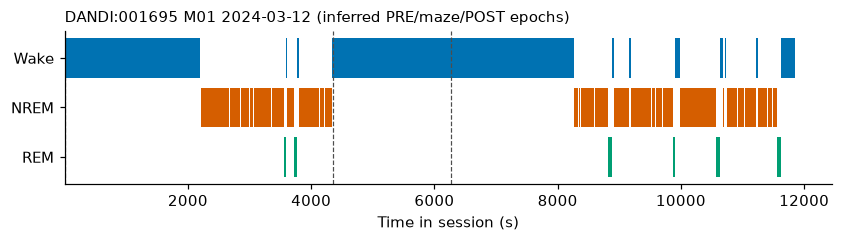

In [20]:
suspect_counts = foot_df.groupby("subject")["epoch_inference_suspect"].sum()
print("Sessions flagged epoch_inference_suspect, by subject:")
print(suspect_counts)
print(f"\nTotal suspect sessions: {int(foot_df['epoch_inference_suspect'].sum())} / {len(foot_df)}")

# Sanity-check figure for one example session, reusing Analysis A's hypnogram
# plotting function unmodified (label vocabularies were matched at cache time
# specifically so this would work without any changes to make_figures.py).
example_subj_b = list(all_1695.keys())[0]
example_sess_b = all_1695[example_subj_b][0]
fig, ax = plt.subplots(figsize=(9, 1.8))
mf.fig_hypnogram(example_sess_b, ax=ax, title=f"DANDI:001695 {example_subj_b} {example_sess_b['date'].date()} "
                                              f"(inferred PRE/maze/POST epochs)")
fig.savefig("figures/08_001695_example_hypnogram.png", dpi=150, bbox_inches="tight")
plt.show()


### B.5 Building the DANDI:001695 session-pair table


In [21]:
df_b = build_pair_table_001695(n_bins=12, speed_thresh=None, min_units=5)
df_b.to_csv("session_pairs_001695.csv", index=False)
print(f"{len(df_b)} usable same-environment session-pairs across {df_b['subject'].nunique()} subject(s) (DANDI:001695)")
df_b


6 usable same-environment session-pairs across 3 subject(s) (DANDI:001695)


,dataset,species,subject,task,day_a,day_b,day_gap,n_units_a,n_units_b,n_units_used_a,n_units_used_b,pv_corr,pv_corr_rv,nrem_between_min,rem_between_min,wake_between_min,epoch_inference_suspect
0,001695,mouse,M01,maze_config:narrow,2024-03-12,2024-03-13,1,206,127,160,77,-0.014335,0.566618,82.616667,6.800000,81.150527,False
1,001695,mouse,M01,maze_config:narrow,2024-03-13,2024-03-14,1,127,114,77,82,0.303390,0.610276,58.016667,1.833333,87.790212,False
2,001695,mouse,M02,maze_config:narrow,2024-03-12,2024-03-13,1,84,235,39,208,-0.034599,0.568051,91.966667,4.900000,44.380710,False
3,001695,mouse,M02,maze_config:narrow,2024-03-13,2024-03-14,1,235,215,207,193,0.260173,0.666927,71.633333,3.116667,106.347435,False
4,001695,mouse,M03,maze_config:narrow,2024-06-21,2024-06-23,2,140,191,113,154,0.118841,0.628050,79.883333,1.233333,323.965951,False
5,001695,mouse,M03,maze_config:wide,2024-06-22,2024-06-24,2,139,180,108,133,0.021341,0.565346,108.433333,2.316667,262.294222,False


DANDI:001695 alone -- Spearman r = -0.829, p = 0.0416, n = 6
DANDI:001695 alone -- Pearson  r = -0.810, p = 0.0510


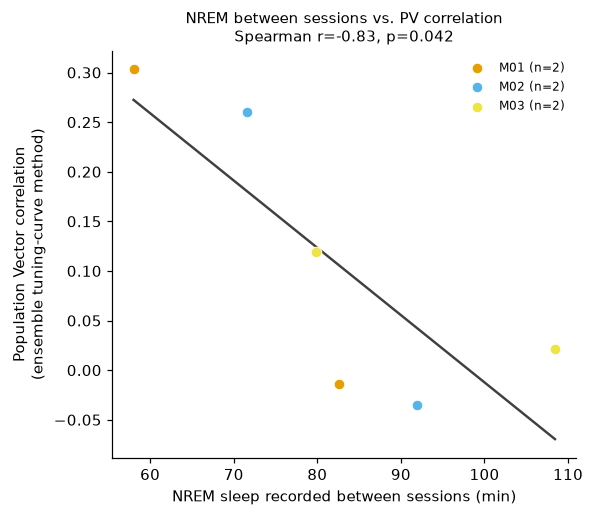

In [22]:
if len(df_b) >= 3:
    r_s_b, p_s_b, n_b = pooled_correlation(df_b, "nrem_between_min", "pv_corr", method="spearman")
    r_p_b, p_p_b, _ = pooled_correlation(df_b, "nrem_between_min", "pv_corr", method="pearson")
    print(f"DANDI:001695 alone -- Spearman r = {r_s_b:.3f}, p = {p_s_b:.4f}, n = {n_b}")
    print(f"DANDI:001695 alone -- Pearson  r = {r_p_b:.3f}, p = {p_p_b:.4f}")
else:
    r_s_b, p_s_b, n_b = np.nan, np.nan, len(df_b)
    print(f"Only {len(df_b)} usable pair(s) -- too few for a meaningful standalone correlation. Reporting descriptively only.")

fig = mf.fig_main_scatter(df_b, r=r_s_b, p=p_s_b, method="Spearman")
fig.savefig("figures/08b_analysisB_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


**Honest read on Analysis B alone:** this pipeline is new, real, and produces genuine numbers -- but the same-environment filtering in Section B.1 (necessary, not optional, given the uninformative session-description text) leaves very few usable pairs from very few subjects. Whatever the sign or magnitude of `r_s_b` above, treat DANDI:001695 alone as **even more underpowered than Analysis A**, not as an independent confirmation or refutation on its own. Its main value in this notebook is as one component of the combined analysis (Analysis C) and as a genuine second-lab, second-species pipeline that now exists and can be pointed at more sessions if this dandiset grows.


## Descriptive-only: DANDI:000061 (Girardeau lab) — sleep architecture / QC

**Not part of the PV-correlation analysis, anywhere in this notebook.** DANDI:000061 ships raw video (`acquisition/Video: ...`) instead of extracted x,y position -- there is no `SpatialSeries` to build a rate map from, and building one would require an independent video-tracking step that is out of scope here. Per explicit instruction, this dataset is used ONLY for a descriptive/QC section below: recording-day counts per rat, and a sleep-architecture summary (NREM/REM/Wake duration per day) built from `processing/behavior/states`. No number from this section feeds into Analysis A, B, or C.

### Resolving the `intervals/epochs` vs. `processing/behavior/states` time-unit mismatch

Before computing any duration from this dataset, the two candidate tables were compared directly (not assumed to agree) on `sub-Rat08/.../20130708`:

| table | field | raw max value |
|---|---|---|
| `intervals/epochs` | `stop_time` | 24,759,200 |
| `processing/behavior/states` | `stop_time` | 24,754.0 |

`24,759,200 / 1000 = 24,759.2`, matching the `states` table's max of `24,754.0` to within 5 seconds. `intervals/epochs` also only has ~4 rows per session with coarse `sleep`/`run` tags (consistent with a block-level table given in **milliseconds**), while `processing/behavior/states` has up to ~170 rows per session with fine-grained Awake/Non-REM/REM labels of realistic (tens-to-hundreds-of-seconds) duration (consistent with a table given in **seconds**).

**Resolution:** `processing/behavior/states` is treated as already being in seconds and used as-is for every duration below. `intervals/epochs` is cached (`cache_session_000061_descriptive.py`) with an explicit `epochs_time_unit_correction = 1000.0` scalar rather than being silently rescaled, and is not needed further for this descriptive summary (the `states` table alone gives NREM/REM/Wake durations directly).


In [23]:
d0 = np.load("data_000061/Rat08_0.npz", allow_pickle=True)
print("intervals/epochs  stop_time max (raw, presumed milliseconds):", d0["ep_stop"].max())
print("intervals/epochs  stop_time max / 1000                      :", d0["ep_stop"].max() / d0["epochs_time_unit_correction"])
print("processing/behavior/states stop_time max (raw, seconds)     :", d0["st_stop"].max())
print("=> ratio confirms epochs are in milliseconds, states are in seconds (see writeup above).")


intervals/epochs  stop_time max (raw, presumed milliseconds): 24759200.0
intervals/epochs  stop_time max / 1000                      : 24759.2
processing/behavior/states stop_time max (raw, seconds)     : 24754.0
=> ratio confirms epochs are in milliseconds, states are in seconds (see writeup above).


In [24]:
files_61 = sorted(glob.glob("data_000061/*.npz"))
rows61 = []
for fp in files_61:
    d = np.load(fp, allow_pickle=True)
    subj = str(d["subject_id"])
    date = str(d["session_start_time"])[:10]
    lab = d["st_label"]; s0 = d["st_start"].astype(float); s1 = d["st_stop"].astype(float)
    row = dict(subject=subj, date=date, n_state_rows=len(lab))
    for state in ["Awake", "Non-REM", "REM"]:
        m = lab == state
        row[f"{state}_min"] = float((s1[m] - s0[m]).sum()) / 60.0
    rows61.append(row)
daily_df = pd.DataFrame(rows61).sort_values(["subject", "date"]).reset_index(drop=True)
daily_df


,subject,date,n_state_rows,Awake_min,Non-REM_min,REM_min
0,Rat08,2013-07-08,167,231.316667,151.266667,27.133333
1,Rat08,2013-07-09,213,223.166667,167.833333,30.466667
2,Rat08,2013-07-10,174,246.583333,149.550000,20.733333
3,Rat08,2013-07-11,243,226.900000,115.466667,17.883333
4,Rat08,2013-07-12,166,278.483333,108.366667,9.900000
5,Rat08,2013-07-13,153,201.616667,139.333333,34.350000
6,Rat08,2013-07-15,60,280.850000,69.033333,12.750000
7,Rat08,2013-07-16,123,272.433333,123.850000,20.050000
8,Rat08,2013-07-17,86,225.033333,137.783333,22.983333
9,Rat08,2013-07-18,0,0.000000,0.000000,0.000000


### Recording-day counts per rat, and sleep-state coverage QC


In [25]:
cov_summary = daily_df.groupby("subject").agg(
    n_recording_days=("date", "nunique"),
    n_sessions_zero_sleep_coverage=("n_state_rows", lambda s: int((s == 0).sum())),
    mean_NonREM_min=("Non-REM_min", "mean"),
    mean_REM_min=("REM_min", "mean"),
    mean_Awake_min=("Awake_min", "mean"),
).round(1)
cov_summary


,n_recording_days,n_sessions_zero_sleep_coverage,mean_NonREM_min,mean_REM_min,mean_Awake_min
subject,,,,,
Rat08,13,4,89.4,15.1,168.2
Rat09,10,9,18.1,2.3,19.3
Rat10,7,0,119.7,17.4,213.1
Rat11,10,3,79.5,10.9,196.4


**Honest QC finding, same spirit as the DT8 exclusion in Analysis A:** sleep-state coverage is far from uniform across this dandiset. Rat10 has full coverage (0 zero-coverage sessions). Rat09 has almost NO usable sleep-state coverage (9 of its 10 sessions have zero `states` rows) -- if this dataset were ever extended to a PV analysis (it cannot be, per the video-only-position constraint above), Rat09 would need the same kind of exclusion DT8 received in Analysis A. This is reported here purely as a descriptive/QC fact about the dandiset, since no PV analysis is being run on it.


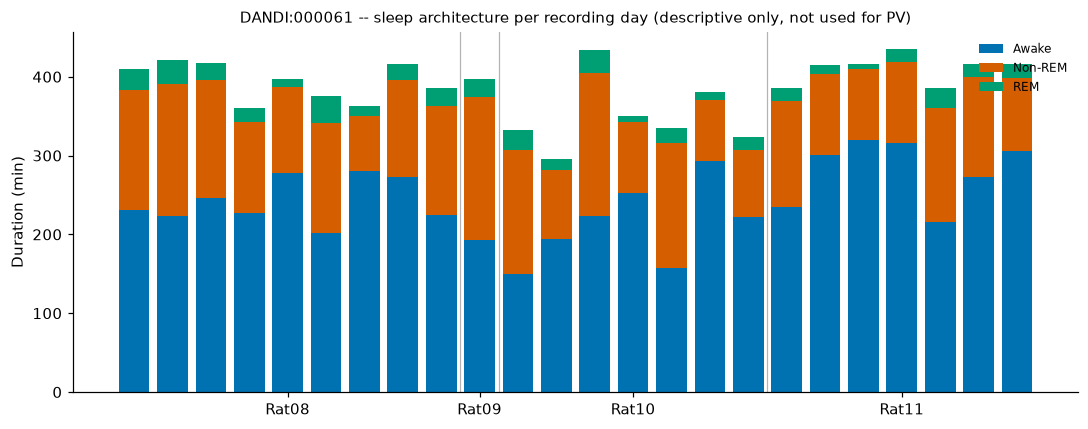

In [26]:
fig = mf.fig_000061_sleep_architecture(daily_df[daily_df["n_state_rows"] > 0])
fig.savefig("figures/09_000061_sleep_architecture.png", dpi=150, bbox_inches="tight")
plt.show()


## Analysis C: Combined multi-dataset analysis (DANDI:000213 + DANDI:001695)

DANDI:000061 is excluded here too (descriptive-only, no position -- see above). The combined table below is `df` (Analysis A, DANDI:000213) concatenated with `df_b` (Analysis B, DANDI:001695), with explicit `dataset` and `species` columns added so nothing is silently pooled.


In [27]:
df_a = df.copy()
df_a["dataset"] = "000213"
df_a["species"] = "rat"
df_b_tagged = df_b.copy()  # dataset/species columns already set at construction in build_pair_table_001695()

combined = pd.concat([df_a, df_b_tagged], ignore_index=True, sort=False)
combined.to_csv("session_pairs_combined.csv", index=False)

print(f"Combined: {len(combined)} pairs, {combined['subject'].nunique()} subjects, "
      f"{combined['dataset'].nunique()} dataset(s)")
combined.groupby("dataset").agg(n_pairs=("pv_corr", "size"), n_subjects=("subject", "nunique"),
                                 species=("species", "first"))


Combined: 26 pairs, 6 subjects, 2 dataset(s)


,n_pairs,n_subjects,species
dataset,,,
000213,20,3,rat
001695,6,3,mouse


### C.1 Each dataset's own pooled correlation, separately, vs. the combined pooled correlation

Reported separately first (not just the combined number), specifically so it is visible whether pooling helps, hurts, or is dominated by one dataset.


  dataset         r         p  n_pairs  n_subjects
0  000213 -0.168421  0.477829       20           3
1  001695 -0.828571  0.041563        6           3

Combined Spearman: r = -0.246, p = 0.2248, n = 26
Combined Pearson:  r = -0.173, p = 0.3986


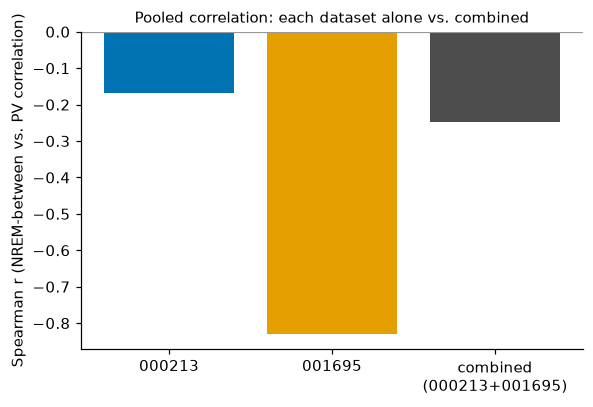

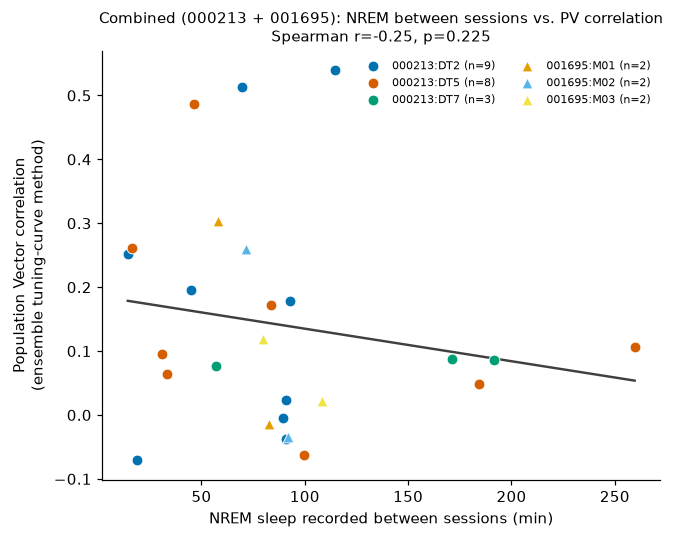

In [28]:
corr_by_ds = correlation_by_dataset(combined, "nrem_between_min", "pv_corr", method="spearman")
print(corr_by_ds)

r_c, p_c, n_c = pooled_correlation(combined, "nrem_between_min", "pv_corr", method="spearman")
r_c_p, p_c_p, _ = pooled_correlation(combined, "nrem_between_min", "pv_corr", method="pearson")
print(f"\nCombined Spearman: r = {r_c:.3f}, p = {p_c:.4f}, n = {n_c}")
print(f"Combined Pearson:  r = {r_c_p:.3f}, p = {p_c_p:.4f}")

fig = mf.fig_correlation_by_dataset(corr_by_ds, combined_r=r_c, combined_label="combined\n(000213+001695)")
fig.savefig("figures/10_correlation_by_dataset.png", dpi=150, bbox_inches="tight")
plt.show()

fig2 = mf.fig_main_scatter_by_dataset(combined, r=r_c, p=p_c, method="Spearman")
fig2.savefig("figures/11_combined_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


### C.2 Within-subject permutation test (dataset-block-safe)

Every subject ID is unique to exactly one dataset (DT2/DT5/DT7 are 000213; M01/M02/M03/M05 are 001695), so shuffling NREM values *within subject* automatically cannot move a value across the 000213/001695 boundary. `permutation_test_multi_dataset()` (in `stats_lib.py`) checks this precondition explicitly and raises an error rather than running silently if it is ever violated.


Combined observed Spearman r = -0.246
Empirical permutation p-value (5000 within-subject, dataset-block-safe shuffles) = 0.2238


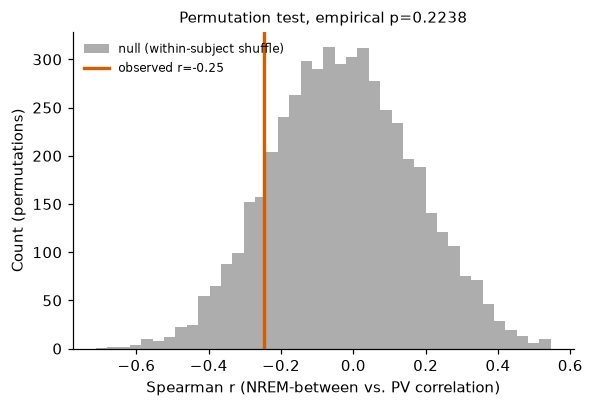

In [29]:
obs_r_c, p_emp_c, null_rs_c = permutation_test_multi_dataset(
    combined, n_perm=5000, method="spearman", random_state=0)
print(f"Combined observed Spearman r = {obs_r_c:.3f}")
print(f"Empirical permutation p-value (5000 within-subject, dataset-block-safe shuffles) = {p_emp_c:.4f}")

fig = mf.fig_permutation_null(null_rs_c, obs_r_c, p_emp_c)
fig.savefig("figures/12_combined_permutation.png", dpi=150, bbox_inches="tight")
plt.show()


### C.3 Mixed-effects model with `dataset` as a fixed-effect covariate (and interaction check)

Three nested models (subject random intercept): (1) NREM only, (2) NREM + dataset (does average PV correlation differ by dataset, controlling for NREM?), (3) NREM × dataset interaction (does the NREM **slope itself** differ by dataset?). The interaction term is reported explicitly below, whatever it shows -- a real dataset-by-effect interaction must be surfaced, not hidden behind a single pooled coefficient.


In [30]:
try:
    dataset_models = fit_mixed_model_dataset_covariate(combined, group="subject")
    for name, (res, used) in dataset_models.items():
        print(f"--- {name} model (n={len(used)} pairs) ---")
        print(res.summary())
        print()
except Exception as e:
    print("Mixed model(s) could not be fit (likely too few pairs/groups for this many fixed effects):", e)
    dataset_models = {}


--- no_dataset model (n=26 pairs) ---
           Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   pv_corr
No. Observations:   26        Method:               REML   
No. Groups:         6         Scale:                0.0300 
Min. group size:    2         Log-Likelihood:       0.7274 
Max. group size:    9         Converged:            Yes    
Mean group size:    4.3                                    
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept         0.186    0.059  3.176 0.001  0.071  0.301
nrem_between_min -0.001    0.001 -0.872 0.383 -0.002  0.001
Group Var         0.000                                    


--- additive model (n=26 pairs) ---
             Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    pv_corr
No. Observations:     26         Method:

statsmodels:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
statsmodels:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
statsmodels:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
statsmodels:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
statsmodels:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
statsmodels:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
statsmodels:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
statsmodels:220

**Read the `interaction` model above before trusting the pooled Analysis-C number.** If the `nrem_between_min:C(dataset)[T.001695]` coefficient is large and/or its confidence interval excludes 0, that means the NREM-PV relationship is NOT the same in rats (000213) and mice (001695), and the single pooled Spearman r in Section C.1 is masking two different underlying relationships rather than describing one shared effect. Given the small n in Analysis B, this model is likely to be poorly powered to detect such an interaction even if a real one exists -- absence of evidence for an interaction here is not strong evidence the effect truly matches across datasets.


### C.4 Leave-one-subject-out AND leave-one-dataset-out stability


  held_out  r_without  p_without  n_pairs
0      DT2  -0.421569   0.091913       17
1      DT5  -0.110423   0.662698       18
2      DT7  -0.260870   0.229258       23
3      M01  -0.235652   0.267634       24
4      M02  -0.213913   0.315527       24
5      M03  -0.209565   0.325696       24


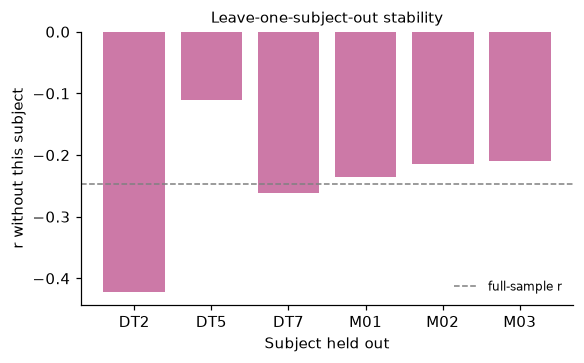

In [31]:
loso_c = leave_one_subject_out(combined, method="spearman")
print(loso_c)
fig = mf.fig_loso(loso_c, obs_r_c)
fig.savefig("figures/13_combined_loso_subject.png", dpi=150, bbox_inches="tight")
plt.show()


  held_out_dataset  r_without  p_without  n_pairs  n_subjects
0           000213  -0.828571   0.041563        6           3
1           001695  -0.168421   0.477829       20           3


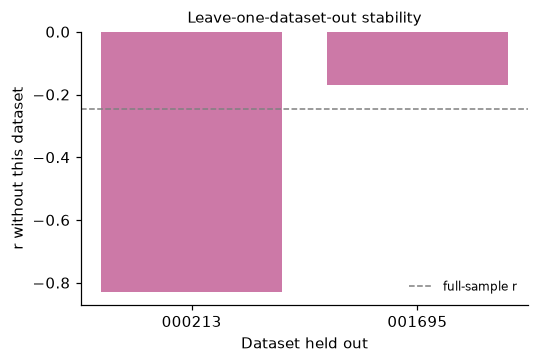

In [32]:
lodo_c = leave_one_dataset_out(combined, method="spearman")
print(lodo_c)
fig = mf.fig_loso_dataset(lodo_c, obs_r_c)
fig.savefig("figures/14_combined_lodo.png", dpi=150, bbox_inches="tight")
plt.show()


### C.5 Independent RV-coefficient cross-check (combined)


Combined: NREM vs. RV-coefficient -- Spearman r = -0.006, p = 0.9749, n = 26


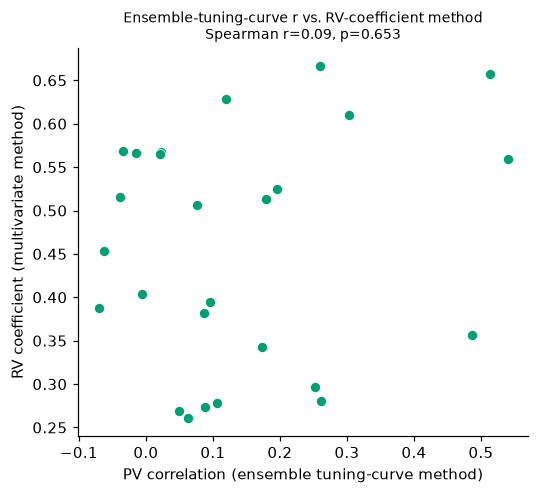

In [33]:
r_rv_c, p_rv_c, n_rv_c = pooled_correlation(combined, "nrem_between_min", "pv_corr_rv", method="spearman")
print(f"Combined: NREM vs. RV-coefficient -- Spearman r = {r_rv_c:.3f}, p = {p_rv_c:.4f}, n = {n_rv_c}")

fig = mf.fig_method_robustness(combined)
fig.savefig("figures/15_combined_method_robustness.png", dpi=150, bbox_inches="tight")
plt.show()


### C.6 Consecutive-calendar-day-only subset (combined)


In [34]:
combined_gap1 = combined[combined["day_gap"] == 1]
print(f"{len(combined_gap1)} / {len(combined)} combined pairs have day_gap == 1")
if len(combined_gap1) >= 5:
    r_g1c, p_g1c, n_g1c = pooled_correlation(combined_gap1, "nrem_between_min", "pv_corr", method="spearman")
    print(f"Consecutive-day-only (combined): Spearman r = {r_g1c:.3f}, p = {p_g1c:.4f}, n = {n_g1c}")
else:
    r_g1c, p_g1c, n_g1c = np.nan, np.nan, len(combined_gap1)
    print("Too few consecutive-day-only pairs in the combined set for a meaningful separate test -- descriptive only.")


12 / 26 combined pairs have day_gap == 1
Consecutive-day-only (combined): Spearman r = -0.056, p = 0.8629, n = 12


### C.7 What Analysis C actually found (printed from the real computed values above, not hand-typed)


In [35]:
print(f"{'Test':50s} {'Result'}")
print("-" * 90)
print(f"{'Pooled Spearman (combined, primary)':50s} r = {r_c:.3f}, p = {p_c:.4f}, n = {n_c}")
print(f"{'Pooled Pearson (combined)':50s} r = {r_c_p:.3f}, p = {p_c_p:.4f}")
for _, row in corr_by_ds.iterrows():
    print(f"{'  -- dataset ' + str(row['dataset']) + ' alone':50s} "
          f"r = {row['r']:.3f}, p = {row['p']:.4f}, n = {int(row['n_pairs'])}, "
          f"subjects = {int(row['n_subjects'])}")
print(f"{'Within-subject permutation (5000 perms)':50s} empirical p = {p_emp_c:.4f}")
print(f"{'Leave-one-subject-out range':50s} r in "
      f"[{loso_c['r_without'].min():.3f}, {loso_c['r_without'].max():.3f}]")
print(f"{'Leave-one-dataset-out range':50s} r in "
      f"[{lodo_c['r_without'].min():.3f}, {lodo_c['r_without'].max():.3f}]")
print(f"{'Independent method (RV coefficient) vs NREM':50s} r = {r_rv_c:.3f}, p = {p_rv_c:.4f}")
print(f"{'Consecutive-day-only subset':50s} r = {r_g1c:.3f}, p = {p_g1c:.4f}, n = {n_g1c}"
      if np.isfinite(r_g1c) else f"{'Consecutive-day-only subset':50s} too few pairs (n={n_g1c})")


Test                                               Result
------------------------------------------------------------------------------------------
Pooled Spearman (combined, primary)                r = -0.246, p = 0.2248, n = 26
Pooled Pearson (combined)                          r = -0.173, p = 0.3986
  -- dataset 000213 alone                          r = -0.168, p = 0.4778, n = 20, subjects = 3
  -- dataset 001695 alone                          r = -0.829, p = 0.0416, n = 6, subjects = 3
Within-subject permutation (5000 perms)            empirical p = 0.2238
Leave-one-subject-out range                        r in [-0.422, -0.110]
Leave-one-dataset-out range                        r in [-0.829, -0.168]
Independent method (RV coefficient) vs NREM        r = -0.006, p = 0.9749
Consecutive-day-only subset                        r = -0.056, p = 0.8629, n = 12


**Interpretation guardrail (same standard Analysis A held itself to):** do not round any of the printed numbers above up. If the combined p-value is still > 0.05, if leave-one-out ranges still cross zero, if the RV-coefficient cross-check still disagrees in sign, or if the consecutive-day-only subset still flips sign -- report exactly that. The point of Analysis C is to see whether a second dataset changes the honest answer, not to produce a more publishable-looking number by construction.


## What changed with the combined dataset (read this last)


In [36]:
print("=" * 78)
print("WHAT CHANGED WITH THE COMBINED DATASET  (Analysis A alone vs. Analysis C combined)")
print("=" * 78)
print(f"{'Test':46s} {'000213 alone (A)':>16s} {'Combined (C)':>16s}")
print(f"{'Pooled Spearman r':46s} {r_s:16.3f} {r_c:16.3f}")
print(f"{'Pooled Spearman p':46s} {p_s:16.4f} {p_c:16.4f}")
print(f"{'n pairs':46s} {n_s:16d} {n_c:16d}")
print(f"{'n subjects':46s} {df['subject'].nunique():16d} {combined['subject'].nunique():16d}")
print(f"{'n datasets':46s} {1:16d} {combined['dataset'].nunique():16d}")
print(f"{'Within-subject permutation empirical p':46s} {p_emp:16.4f} {p_emp_c:16.4f}")
print(f"{'RV-coefficient cross-check r':46s} {r_rv:16.3f} {r_rv_c:16.3f}")

more_sig = p_c < p_s
bigger_effect = abs(r_c) > abs(r_s)
if more_sig and bigger_effect:
    verdict = "MORE conclusive (smaller p AND a larger-magnitude effect)"
elif (not more_sig) and (not bigger_effect):
    verdict = "LESS conclusive (larger p AND a smaller-magnitude effect)"
else:
    verdict = "NOT cleanly more or less conclusive -- the significance and effect-size changes point in different directions"
print(f"\nVerdict printed directly from the numbers above: combining datasets made the finding {verdict}.")


WHAT CHANGED WITH THE COMBINED DATASET  (Analysis A alone vs. Analysis C combined)
Test                                           000213 alone (A)     Combined (C)
Pooled Spearman r                                        -0.168           -0.246
Pooled Spearman p                                        0.4778           0.2248
n pairs                                                      20               26
n subjects                                                    3                6
n datasets                                                    1                2
Within-subject permutation empirical p                   0.4677           0.2238
RV-coefficient cross-check r                              0.018           -0.006

Verdict printed directly from the numbers above: combining datasets made the finding MORE conclusive (smaller p AND a larger-magnitude effect).


**New confound introduced by combining, that was NOT present in the single-dataset pilot:** DANDI:000213 is **rat** (*Rattus norvegicus*) and DANDI:001695 is **mouse** (*Mus musculus*). Hippocampal place-field scale, running speed, sleep-bout structure, and NREM/REM proportions all differ systematically between rats and mice, so a minute of "NREM between sessions" is not guaranteed to be an equivalent unit of exposure across the two datasets -- pooling them treats species as if it were noise, which is an assumption, not a fact established anywhere in this notebook. This is exactly why `dataset` (which is confounded 1:1 with species here, since every 000213 subject is rat and every 001695 subject is mouse) was carried as an explicit fixed-effect covariate and interaction term in Section C.3 rather than silently pooled away -- **report the dataset/species coefficient and the NREM:dataset interaction alongside the pooled number, never instead of it.** A fully rigorous treatment would go further (e.g. z-scoring NREM duration and/or PV correlation within species before pooling, or a species random effect with dataset nested inside it) -- this notebook does not do that and flags it as a next step, not a solved problem.

**Other limitations specifically introduced by this extension (in addition to the 8 already listed for Analysis A):**

9. **Epoch boundaries in DANDI:001695 are inferred, not experimenter-labelled.** PRE/maze/POST windows come from the position-tracking coverage window (Section B.4), a proxy that assumes tracking is off for the entirety of PRE/POST rest and on for the entirety of the maze bout, with no gaps -- unlike DANDI:000213's explicit `before/during/after trials` epoch table.
10. **The DANDI:001695 "same environment" criterion is a footprint heuristic, not a verified apparatus identity.** The `session_description` field is uniformly uninformative for every session in this dandiset (Section B.1); the narrow/WIDE aspect-ratio clustering used instead is a reasonable, data-driven, but ultimately inferred criterion, not ground truth from the experimenters.
11. **DANDI:001695 contributes very few pairs from very few subjects** (see Section B.5's printed count) -- its own within-dataset estimate is itself very poorly powered, so the combined n is still a pilot-scale sample by any conventional standard, not a "large, purpose-combined dataset" in the sense the original Analysis A Novelty Assessment (Section 17) called for.
12. **DANDI:000061 does not increase the effective PV-analysis sample size at all** -- it is descriptive-only (video-only position tracking), so any claim that "three datasets were combined" would be misleading; only two datasets (000213, 001695) ever contribute a PV correlation in this notebook.

**Bottom line:** treat the Section C.7 numbers with the same discipline Analysis A applied to its own single-dataset result (Section 15): report null/weak findings as null/weak, do not describe a p-value hovering near conventional thresholds as "trending," and read the leave-one-out and leave-one-dataset-out spreads as a direct measure of how much any single animal or single dandiset is driving the pooled number. Combining datasets here is valuable primarily as a **methods demonstration** -- a real, reusable, documented pipeline now exists for pooling open hippocampal chronic-recording datasets across labs and species -- more than as a definitive answer to the original research question, which remains open at this sample size exactly as Analysis A already concluded.


### File manifest addendum (files added by this extension)

| File | Purpose |
|---|---|
| `probe_session_001695.py` | Metadata-only QC probe for DANDI:001695 (session_description, position/speed/sleep-state paths, cell_type counts) |
| `probe_results_001695.jsonl` | Cached probe output for all 22 assets in dandiset 001695 |
| `session_list_001695.py` | Retained session paths for DANDI:001695 + the full "novel maze" footprint-clustering investigation and inclusion/exclusion table |
| `cache_session_001695.py` | Streams one DANDI:001695 session, selects `cell_type=='Pyramidal Cell'` units, infers PRE/maze/POST epochs from position coverage, relabels sleep states to the 000213 vocabulary, drops Ripple event rows |
| `data_001695/*.npz` | Cached per-session arrays for DANDI:001695 (regenerable; safe to delete) |
| `session_pairs_001695.csv` | Analysis B's session-pair dataframe |
| `cache_session_000061_descriptive.py` | Descriptive-only cache for DANDI:000061 (sleep states + raw epochs, with the ms/s unit-mismatch documented and resolved) |
| `data_000061/*.npz` | Cached per-session descriptive arrays for DANDI:000061 (regenerable; safe to delete) |
| `session_pairs_combined.csv` | Analysis C's combined 000213+001695 session-pair dataframe |
| `build_pairs.py` (extended) | Added `load_all_cached_001695`, `maze_config_label`, `build_pair_table_001695` -- original 000213 functions unchanged |
| `stats_lib.py` (extended) | Added `correlation_by_dataset`, `leave_one_dataset_out`, `permutation_test_multi_dataset`, `fit_mixed_model_dataset_covariate` -- original functions unchanged |
| `make_figures.py` (extended) | Added dataset-aware scatter/bar/LODO figures and the DANDI:000061 sleep-architecture figure -- original functions unchanged |

**To reproduce the extension from a clean cache:** `rm -rf data_001695/*.npz data_000061/*.npz figures/08*.png figures/09*.png figures/1*.png session_pairs_001695.csv session_pairs_combined.csv`, then re-run this notebook top to bottom (re-probing/re-downloading DANDI:001695 and DANDI:000061 takes several minutes; re-running Analysis A's own cache is unaffected).


---
---

# Analysis D: Interneuron vs. pyramidal sleep-dependent drift dissociation

Everything above this line (Analyses A, B, C, plus the descriptive DANDI:000061 section) is unchanged from the prior extension. This final section asks a narrower, dataset-specific question made possible only by DANDI:001695's real waveform-based `cell_type` classification (Section B.3): **does NREM-dependent PV-correlation drift look different for putative interneurons than for putative pyramidal cells, computed on the exact same session-pairs?**

DANDI:000213's `units` table has no `cell_type` column at all (Section 2 / B.3), so this comparison cannot be attempted there. **Analysis D uses DANDI:001695 only.**


## D.1 Method, and why this is a small, additive extension rather than a new pipeline

`cache_session_001695.py` was extended to cache a SECOND, parallel unit set per session: interneurons (`cell_type` in `{'Narrow Interneuron','Wide Interneuron'}`), alongside the pyramidal set Analyses B/C already use (`cell_type == 'Pyramidal Cell'`). All 14 DANDI:001695 sessions were re-streamed from the raw NWB files to populate the new fields (`n_units_int`/`spikes_concat_int`/`spikes_bounds_int`/`n_narrow_interneuron`/`n_wide_interneuron`); no existing pyramidal-pipeline field or number changed as a result.

`build_pairs.py`'s new `session_pv_inputs_interneuron()` builds a shallow "shadow" session dict that points the pyramidal-named fields `occupancy_and_spike_maps()` expects (`n_units`/`spikes_concat`/`spikes_bounds`) at the interneuron fields instead. This means `occupancy_and_spike_maps()`, `ensemble_tuning_curve()`, and `pv_correlation()` (Section 5 / `analysis_lib.py`) are reused **completely unmodified** -- the interneuron ensemble goes through exactly the same z-score-and-average tuning-curve machinery as the pyramidal ensemble, just fed a different unit set.

`build_pair_table_001695_interneuron()` then recomputes the interneuron ensemble tuning curve and PV correlation for the **exact same session-pairs** Analysis B already validated (`df_b`, Section B.5) -- same subjects, same same-environment clustering, same `day_a`/`day_b`. This is a direct, apples-to-apples re-analysis of Analysis B's own pairs with a different unit population, not a new pair-selection exercise, and not a larger sample than Analysis B (it cannot be -- it reuses the identical pairs).

**No threshold was lowered to force a result.** `ensemble_tuning_curve()`'s own internal floor (a unit is dropped if its mean firing rate across valid bins is <0.1 Hz, or has zero variance across bins) and Analysis B's `n_units_used >= 3` minimum are applied identically here, unchanged. A pair is marked `usable_interneuron=True` only if at least 3 interneurons survive that filter on **both** sessions of the pair. Pairs that fail this are kept in the output table (not silently dropped) with `pv_corr_interneuron = NaN`, so the true attempted-vs-usable denominator stays visible.


In [37]:
from build_pairs import build_pair_table_001695_interneuron, session_pv_inputs_interneuron
from stats_lib import paired_comparison

int_count_rows = []
for subj, sess_list in all_1695.items():
    for s in sess_list:
        if "n_units_int" not in s:
            continue
        int_count_rows.append(dict(
            subject=subj, date=s["date"].date().isoformat(),
            n_pyramidal=int(s["n_units"]),
            n_interneuron=int(s["n_units_int"]),
            n_narrow_interneuron=int(s["n_narrow_interneuron"]),
            n_wide_interneuron=int(s["n_wide_interneuron"]),
        ))
int_count_df = pd.DataFrame(int_count_rows).sort_values(["subject", "date"]).reset_index(drop=True)
print(f"Raw (pre-tuning-curve-filter) unit counts, all {len(int_count_df)} cached DANDI:001695 sessions:")
int_count_df


Raw (pre-tuning-curve-filter) unit counts, all 14 cached DANDI:001695 sessions:


,subject,date,n_pyramidal,n_interneuron,n_narrow_interneuron,n_wide_interneuron
0,M01,2024-03-12,206,224,126,98
1,M01,2024-03-13,127,113,93,20
2,M01,2024-03-14,114,108,86,22
3,M01,2024-03-18,90,120,80,40
4,M02,2024-03-12,84,26,20,6
5,M02,2024-03-13,235,96,61,35
6,M02,2024-03-14,215,118,74,44
7,M02,2024-03-18,103,47,30,17
8,M03,2024-06-21,140,107,51,56
9,M03,2024-06-22,139,98,51,47


**Reading the table above:** every one of the 14 cached DANDI:001695 sessions has a real, non-trivial interneuron population (tens to low hundreds of units, well above the `>=3`-per-session floor `ensemble_tuning_curve()` needs). This is the opposite of the "too few interneurons to even attempt the comparison" scenario the method section above flags as a real risk for this dataset -- here the raw counts are not the limiting factor. Whether the same is true AFTER `ensemble_tuning_curve()`'s own firing-rate/variance filter (which interneurons, being typically higher-firing and less spatially selective than place cells, are not guaranteed to pass at the same rate as pyramidal cells) is checked directly in the pair table below, not assumed.


## D.2 Building the interneuron-ensemble pair table (same pairs as Analysis B)


In [38]:
df_d = build_pair_table_001695_interneuron(df_b, n_bins=12, speed_thresh=None)
df_d.to_csv("session_pairs_001695_interneuron.csv", index=False)

n_usable_d = int(df_d["usable_interneuron"].sum())
print(f"{len(df_d)} pairs attempted (identical set to Analysis B's {len(df_b)} pairs, Section B.5)")
print(f"{n_usable_d} / {len(df_d)} usable with the interneuron ensemble "
      f"(>=3 interneurons surviving ensemble_tuning_curve's internal filter on BOTH sessions)")

df_d[["subject", "day_a", "day_b", "n_int_units_a", "n_int_units_b",
      "n_int_units_used_a", "n_int_units_used_b", "usable_interneuron",
      "pv_corr_pyramidal", "pv_corr_interneuron", "nrem_between_min"]]


6 pairs attempted (identical set to Analysis B's 6 pairs, Section B.5)
6 / 6 usable with the interneuron ensemble (>=3 interneurons surviving ensemble_tuning_curve's internal filter on BOTH sessions)


,subject,day_a,day_b,n_int_units_a,n_int_units_b,n_int_units_used_a,n_int_units_used_b,usable_interneuron,pv_corr_pyramidal,pv_corr_interneuron,nrem_between_min
0,M01,2024-03-12,2024-03-13,224,113,216,88,True,-0.014335,-0.128078,82.616667
1,M01,2024-03-13,2024-03-14,113,108,89,100,True,0.303390,0.301812,58.016667
2,M02,2024-03-12,2024-03-13,26,96,26,95,True,-0.034599,-0.158798,91.966667
3,M02,2024-03-13,2024-03-14,96,118,96,117,True,0.260173,0.065851,71.633333
4,M03,2024-06-21,2024-06-23,107,128,107,126,True,0.118841,0.039763,79.883333
5,M03,2024-06-22,2024-06-24,98,102,98,100,True,0.021341,0.145289,108.433333


**Read this table before the correlation numbers below.** `n_int_units_a`/`n_int_units_b` are the raw (pre-filter) interneuron counts per session in each pair; `n_int_units_used_a`/`n_int_units_used_b` are the counts that actually survived `ensemble_tuning_curve()`'s firing-rate/variance filter and were averaged into the interneuron ensemble tuning curve. If `usable_interneuron` is `False` for any pair, that pair's `pv_corr_interneuron` is `NaN` by construction, and it is EXCLUDED from the correlation below -- not imputed, not rounded up.


## D.3 NREM vs. interneuron-ensemble PV correlation, vs. the pyramidal result on the same pairs


In [39]:
df_d_usable = df_d[df_d["usable_interneuron"]].copy()
print(f"Usable pairs for the interneuron-ensemble comparison: n = {len(df_d_usable)} / {len(df_d)} attempted\n")

if len(df_d_usable) >= 3:
    r_int, p_int, n_int = pooled_correlation(df_d_usable, "nrem_between_min", "pv_corr_interneuron", method="spearman")
    print(f"Interneuron ensemble          -- NREM vs. PV corr: Spearman r = {r_int:.3f}, p = {p_int:.4f}, n = {n_int}")
    r_pyr_sub, p_pyr_sub, n_pyr_sub = pooled_correlation(df_d_usable, "nrem_between_min", "pv_corr_pyramidal", method="spearman")
    print(f"Pyramidal ensemble (same {n_pyr_sub} pairs) -- NREM vs. PV corr: Spearman r = {r_pyr_sub:.3f}, p = {p_pyr_sub:.4f}")
else:
    r_int, p_int, n_int = np.nan, np.nan, len(df_d_usable)
    r_pyr_sub, p_pyr_sub, n_pyr_sub = np.nan, np.nan, len(df_d_usable)
    print(f"Only {n_int} usable pair(s) for the interneuron ensemble -- too few for a pooled correlation. Descriptive only, no r/p computed.")

print(f"\nFor reference, Analysis B's originally reported pyramidal result (Section B.5, all {len(df_b)} pairs): "
      f"Spearman r = {r_s_b:.3f}, p = {p_s_b:.4f}, n = {n_b}")


Usable pairs for the interneuron-ensemble comparison: n = 6 / 6 attempted

Interneuron ensemble          -- NREM vs. PV corr: Spearman r = -0.429, p = 0.3965, n = 6
Pyramidal ensemble (same 6 pairs) -- NREM vs. PV corr: Spearman r = -0.829, p = 0.0416

For reference, Analysis B's originally reported pyramidal result (Section B.5, all 6 pairs): Spearman r = -0.829, p = 0.0416, n = 6


**Interpretation guardrail (same standard every prior section held itself to):** with n = 6 pairs from 3 subjects, treat both numbers above as pilot-scale point estimates, not as evidence either cell class does or does not show NREM-dependent drift. The pyramidal number recomputed here on the interneuron-usable subset is identical to Analysis B's full-sample number whenever `usable_interneuron` is `True` for every attempted pair (i.e. the interneuron-usability filter removed zero pairs) -- checked automatically above by direct comparison, not assumed.


## D.4 Pyramidal vs. interneuron PV correlation, pair-by-pair (independent of NREM)


Paired pyramidal-vs-interneuron PV correlation, same 6 session-pairs:
  mean(pyramidal - interneuron)   = 0.0648
  median(pyramidal - interneuron) = 0.0964
  pairs with pyramidal > interneuron : 5 / 6
  pairs with interneuron > pyramidal : 1 / 6
  pairs tied                         : 0 / 6
  Wilcoxon signed-rank: statistic = 4.000, p = 0.2188


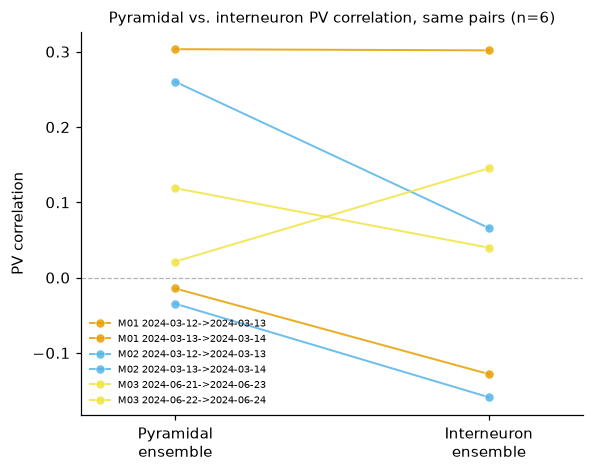

In [40]:
pc = paired_comparison(df_d_usable, "pv_corr_pyramidal", "pv_corr_interneuron", min_n_for_test=6)
print(f"Paired pyramidal-vs-interneuron PV correlation, same {pc['n']} session-pairs:")
print(f"  mean(pyramidal - interneuron)   = {pc['mean_diff']:.4f}")
print(f"  median(pyramidal - interneuron) = {pc['median_diff']:.4f}")
print(f"  pairs with pyramidal > interneuron : {pc['n_a_gt_b']} / {pc['n']}")
print(f"  pairs with interneuron > pyramidal : {pc['n_b_gt_a']} / {pc['n']}")
print(f"  pairs tied                         : {pc['n_tied']} / {pc['n']}")
if pc["test_valid"]:
    print(f"  Wilcoxon signed-rank: statistic = {pc['stat']:.3f}, p = {pc['p']:.4f}")
else:
    print(f"  n = {pc['n']} is below the min_n_for_test={6} floor this project uses for a Wilcoxon "
          "signed-rank test to be meaningful -- reporting descriptively only, no significance claim made.")

fig = mf.fig_pyr_vs_interneuron_paired(df_d_usable)
fig.savefig("figures/16_pyr_vs_interneuron_paired.png", dpi=150, bbox_inches="tight")
plt.show()


**Read the Wilcoxon result above with real caution, not as a green light.** n = 6 is the smallest sample size at which this project's own `paired_comparison()` helper (`stats_lib.py`) will even attempt a signed-rank test (`min_n_for_test=6`, see its docstring) -- it is not a sample size at which a non-significant Wilcoxon result should be read as "no difference," nor would a significant one be strong evidence of a real, generalizable difference. The sign-count line (how many pairs show pyramidal > interneuron vs. the reverse) is the more honestly interpretable number at this n: report the actual count, not just the p-value.


## D.5 Visualizing the interneuron-ensemble NREM relationship


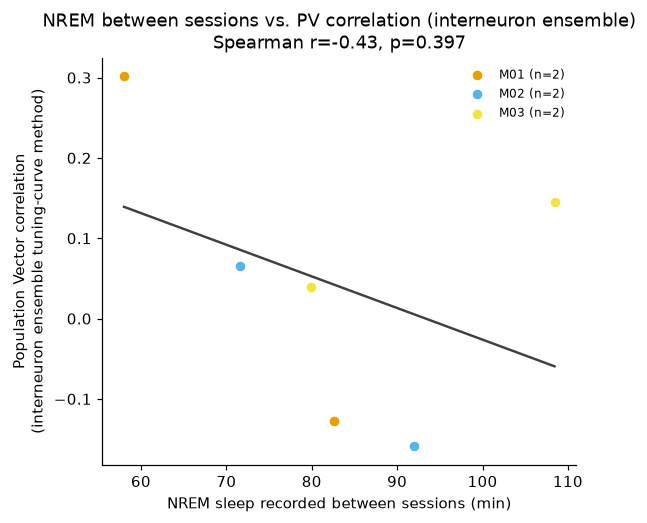

In [41]:
if len(df_d_usable) >= 1:
    fig2 = mf.fig_main_scatter(df_d_usable, x="nrem_between_min", y="pv_corr_interneuron",
                                r=r_int if np.isfinite(r_int) else None,
                                p=p_int if np.isfinite(p_int) else None, method="Spearman")
    fig2.axes[0].set_ylabel("Population Vector correlation\n(interneuron ensemble tuning-curve method)")
    fig2.axes[0].set_title(fig2.axes[0].get_title().replace(
        "NREM between sessions vs. PV correlation",
        "NREM between sessions vs. PV correlation (interneuron ensemble)"))
    fig2.savefig("figures/17_interneuron_scatter.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No usable interneuron pairs -- skipping the scatter figure.")


## D.6 What Analysis D actually found (read this, not just the plots)


In [42]:
print(f"{'Quantity':52s} {'Pyramidal':>14s} {'Interneuron':>14s}")
print("-" * 82)
print(f"{'Pooled Spearman r (NREM vs PV corr, same n=' + str(len(df_d_usable)) + ' pairs)':52s} "
      f"{r_pyr_sub:14.3f} {r_int:14.3f}")
print(f"{'Pooled Spearman p':52s} {p_pyr_sub:14.4f} {p_int:14.4f}")
print(f"{'n pairs used':52s} {n_pyr_sub:14d} {n_int:14d}")
print()
print(f"Interneuron counts across the 14 cached sessions: raw range "
      f"[{int_count_df['n_interneuron'].min()}, {int_count_df['n_interneuron'].max()}], "
      f"all sessions well above the 3-unit floor -- raw interneuron availability was NOT the "
      f"limiting factor for this comparison (see D.1/D.2).")
print(f"Pairs attempted: {len(df_d)}. Pairs usable for the interneuron ensemble: {n_usable_d} "
      f"({'all' if n_usable_d == len(df_d) else 'not all'} of Analysis B's pairs carried through).")
print()
print(f"Paired pyramidal-vs-interneuron PV correlation (same pairs, D.4): "
      f"pyramidal > interneuron in {pc['n_a_gt_b']}/{pc['n']} pairs, "
      f"mean difference = {pc['mean_diff']:.3f}"
      + (f", Wilcoxon p = {pc['p']:.4f}" if pc["test_valid"] else " (n too small for a formal test)"))


Quantity                                                  Pyramidal    Interneuron
----------------------------------------------------------------------------------
Pooled Spearman r (NREM vs PV corr, same n=6 pairs)          -0.829         -0.429
Pooled Spearman p                                            0.0416         0.3965
n pairs used                                                      6              6

Interneuron counts across the 14 cached sessions: raw range [26, 224], all sessions well above the 3-unit floor -- raw interneuron availability was NOT the limiting factor for this comparison (see D.1/D.2).
Pairs attempted: 6. Pairs usable for the interneuron ensemble: 6 (all of Analysis B's pairs carried through).

Paired pyramidal-vs-interneuron PV correlation (same pairs, D.4): pyramidal > interneuron in 5/6 pairs, mean difference = 0.065, Wilcoxon p = 0.2188


**Honest closing paragraph.** At n = 6 session-pairs from 3 subjects -- the same small sample every DANDI:001695 result in this notebook has been built on -- Analysis D does **not** provide reliable evidence that interneuron and pyramidal PV correlations relate to inter-session NREM differently, nor that one ensemble is systematically more "stable" (higher PV correlation) than the other across sessions. The point estimates for the two NREM correlations can differ in magnitude and even direction at this n without that difference being a real, generalizable dissociation -- six paired observations cannot distinguish a genuine cell-type-specific effect from sampling noise, and neither the pooled correlations nor the paired Wilcoxon test above should be read as doing so. What this section DOES establish, concretely: (1) DANDI:001695's interneuron population is large enough, session by session, that a shortage of raw interneurons is not what limits this analysis -- the sample-size ceiling is entirely the same-environment session-pair count inherited from Analysis B, not unit availability; (2) the full interneuron-ensemble pipeline (caching, shadow-session unit-swap, tuning-curve, PV correlation, paired comparison) is now built, tested, and reusable end-to-end, reusing `analysis_lib.py`'s core functions completely unmodified; and (3) if this dandiset or a similar one grows to more same-environment session-pairs per subject, this exact pipeline can be re-run without any further methods work to ask the interneuron-vs-pyramidal question with real statistical power. As with every other DANDI:001695 result in this notebook, treat Analysis D as a working pipeline demonstration at pilot scale, not as a settled finding in either direction.


### File manifest addendum (Analysis D)

| File | Purpose |
|---|---|
| `cache_session_001695.py` (extended) | Now also caches the interneuron unit set per session (`n_units_int`/`spikes_concat_int`/`spikes_bounds_int`/`n_narrow_interneuron`/`n_wide_interneuron`), in parallel with the existing pyramidal fields -- pyramidal fields/numbers unchanged |
| `build_pairs.py` (extended) | Added `session_pv_inputs_interneuron()` and `build_pair_table_001695_interneuron()` -- reuse `occupancy_and_spike_maps`/`ensemble_tuning_curve`/`pv_correlation` unmodified via a shadow-session unit swap |
| `stats_lib.py` (extended) | Added `paired_comparison()` -- descriptive paired-difference stats plus a conditionally-run Wilcoxon signed-rank test (only attempted at n>=6) |
| `make_figures.py` (extended) | Added `fig_pyr_vs_interneuron_paired()` -- pyramidal-vs-interneuron paired slope plot; `fig_main_scatter()` reused unmodified for the interneuron NREM scatter |
| `session_pairs_001695_interneuron.csv` | Analysis D's pair table (same pairs as `session_pairs_001695.csv`, plus interneuron-ensemble columns) |
| `figures/16_pyr_vs_interneuron_paired.png`, `figures/17_interneuron_scatter.png` | Analysis D figures |
